# 7002 Big Data Technologies – Practical 1
## Chicago Crime: Distributed ETL, EDA, Spatio-Temporal Clustering and Predictive Modelling with Apache Spark

**Data sources used**

| Role | Dataset | Why it was chosen |
|---|---|---|
| Primary (large) | *Crimes – 2001 to Present* (Kaggle `utkarshx27/crimes-2001-to-present`, ≈ 8 M rows, ≈ 1.8 GB CSV) | Full history of Chicago PD incident records with timestamp, coordinates, district, beat, community area, crime type and arrest flag – large enough to need distributed processing. |
| Secondary | *Census – Selected socio-economic indicators in Chicago 2008–2012* (Kaggle `umermjd11/...`) | One row per community area (77) with poverty, unemployment, income and hardship index – joins on `community_area`, and doubles as the small **Community Names** table for the broadcast join. |
| Weather | *The Weather Dataset* (Kaggle `guillemservera/global-daily-climate-data`): daily readings for ≈ 1,250 cities from Meteostat, filtered to the Chicago station | The brief asks to correlate *weather events ingested in Task 1* with crime, and neither crime/census source contains weather. |

The `kanzariachref/chicago-crime-public-schools-and-census-data` dataset was **not** used: its crime file is a small sample (≈ 500 rows), which would defeat the point of a distributed pipeline.

**Environment:** PySpark ≥ 3.4 (tested against 3.5 / 4.0 APIs), pandas, matplotlib, seaborn, scipy, scikit-learn, pyarrow.
> *Windows note:* local Parquet writes need `HADOOP_HOME` pointing to a folder containing `bin\winutils.exe` and `hadoop.dll` that match your Hadoop version. The first code cell sets `HADOOP_HOME` (edit the path there) and must run **before** any SparkSession exists: the JVM reads the variable only once, at start-up, so after changing it you must restart the kernel. Otherwise, run the notebook on Google Colab / Databricks Community Edition. If you run Java 21, use PySpark 4.x (Spark 3.5 officially supports Java 8/11/17).

Put the Kaggle files in `data/raw/` (the crime CSV, the socio-economic CSV, and `daily_weather.parquet` + `cities.csv` from the weather dataset), then check the paths in the configuration cell.

In [51]:
import os
import sys
import psutil
import pandas
import matplotlib
import seaborn
import scipy
import sklearn
from pyspark.sql import SparkSession

# 1. Access active SparkSession
spark = SparkSession.builder.getOrCreate()
sc = spark.sparkContext
conf = spark.sparkContext.getConf()

# 2. PySpark Version
pyspark_version = spark.version

# 3. Execution Mode & Master URL
master = sc.master
is_local = master.startswith("local")

# 4. System / Environment CPU Cores & RAM
cpu_cores = os.cpu_count()
ram_gb = round(psutil.virtual_memory().total / (1024 ** 3), 1)

# Format cluster vs local string
if is_local:
    env_str = f"local mode on {cpu_cores} CPU cores / {ram_gb} GB RAM"
else:
    env_str = f"cluster mode (master: {master})"

# 5. Adaptive Query Execution (AQE) Status
aqe_enabled = spark.conf.get("spark.sql.adaptive.enabled", "false")

# 6. Shuffle Partitions Count
shuffle_partitions = spark.conf.get("spark.sql.shuffle.partitions")

# 7. Driver Memory Setting
driver_memory = conf.get("spark.driver.memory", "Not explicitly set (default 1g)")

# 8. Python Libraries & Versions
libraries = {
    "pandas": pandas.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__
}

# ------------------------------------------------------------------
# Print Summary
# ------------------------------------------------------------------
print(f"Environment: PySpark {pyspark_version} running in {env_str}, "
      f"with adaptive query execution (AQE) {aqe_enabled}, "
      f"{shuffle_partitions} shuffle partitions and {driver_memory} of driver memory.\n")

print("Python libraries:")
for lib, ver in libraries.items():
    print(f" - {lib}: {ver}")

Environment: PySpark 4.2.0 running in local mode on 12 CPU cores / 15.7 GB RAM, with adaptive query execution (AQE) true, 64 shuffle partitions and 6g of driver memory.

Python libraries:
 - pandas: 3.0.5
 - matplotlib: 3.11.1
 - seaborn: 0.13.2
 - SciPy: 1.18.0
 - scikit-learn: 1.9.0


In [1]:
#!pip install pyspark "pandas<3" pyarrow matplotlib seaborn scipy scikit-learn
import os, re, math, time, glob, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, DataFrame, functions as F, types as T
from pyspark.sql.window import Window
from pyspark import StorageLevel

# ---- Windows / Hadoop set-up: MUST run before the first SparkSession is created ----------------
# The JVM reads HADOOP_HOME only once, when it starts. If a session already exists (e.g. you re-ran
# this cell), the settings below are ignored -> restart the kernel and run this cell first.
HADOOP_HOME = r"C:\Users\jthil\Downloads\hadoop-3.5.0"   # folder containing bin\winutils.exe and bin\hadoop.dll
DRIVER_MEM  = "6g"                                          # about half of your RAM; lower it if the JVM dies ("connection reset")
if os.name == "nt":
    assert os.path.exists(os.path.join(HADOOP_HOME, "bin", "winutils.exe")), f"winutils.exe not found in {HADOOP_HOME}\\bin"
    os.environ["HADOOP_HOME"] = HADOOP_HOME
    os.environ["PATH"] = os.path.join(HADOOP_HOME, "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable               # Python workers must use the notebook's interpreter
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
if SparkSession.getActiveSession() is not None:
    print("WARNING: a SparkSession already exists - HADOOP_HOME / memory settings will NOT apply. Restart the kernel.")

spark = (SparkSession.builder
         .appName("7002-Chicago-Crime")
         .master("local[4]")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.adaptive.enabled", "true")              # AQE: coalesce partitions, handle skewed joins
         .config("spark.sql.adaptive.skewJoin.enabled", "true")
         .config("spark.sql.ansi.enabled", "false")                 # bad casts -> NULL (then quarantined), not job failure
         .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
         .config("spark.sql.session.timeZone", "UTC")               # timestamps are stored as Chicago wall-clock; UTC avoids DST gaps
         .config("spark.sql.parquet.compression.codec", "snappy")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("WARN")
print("Spark", spark.version, "| Hadoop client", spark._jvm.org.apache.hadoop.util.VersionInfo.getVersion())

DATA_DIR  = "data"
CRIME_CSV = (glob.glob(f"{DATA_DIR}/raw/*rime*.csv") or [f"{DATA_DIR}/raw/Crimes_-_2001_to_Present.csv"])[0]
SOCIO_CSV = (glob.glob(f"{DATA_DIR}/raw/*ocioeconomic*.csv") or [f"{DATA_DIR}/raw/socioeconomic.csv"])[0]
WEATHER_PARQUET = (glob.glob(f"{DATA_DIR}/raw/*daily_weather*.parquet") or [f"{DATA_DIR}/raw/daily_weather.parquet"])[0]
WEATHER_CITIES_CSV = f"{DATA_DIR}/raw/cities.csv"
OUT = f"{DATA_DIR}/curated"
print(CRIME_CSV, SOCIO_CSV, WEATHER_PARQUET, sep="\n")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.0 | Hadoop client 3.5.0
data/raw\Crimes_-_2001_to_Present.csv
data/raw\socioeconomic.csv.csv
data/raw\daily_weather.parquet


---
# Task 1 – Distributed Data Engineering & Pipeline Construction

**Pipeline design (medallion style)**

```
raw CSV (all STRING)  ──►  schema enforcement (contract + safe casts + violation log)
                     ──►  data-quality rules (timestamps, duplicates, geography, categories)
                     ──►  quarantine (rejected rows, with reason)       ──► data/curated/_quarantine
                     ──►  feature derivation (time, cyclic hour, location groups)
                     ──►  Parquet, partitionBy(year, district)         ──► data/curated/crimes
```

**Schema Enforcement policy**

1. *Read everything as `STRING`* (`inferSchema=False`). Inference on 8 M rows is slow, needs an extra pass over the data and silently picks the wrong type when a column is mixed (e.g. `Community Area` = `"25"`, `"25.0"`, `""`).
2. *Validate against a column contract* (name → target type). A missing column fails the job fast. Extra columns (e.g. the redundant `Location` string or a pandas index) are dropped.
3. *Cast safely.* Null tokens (`""`, `NA`, `NULL` …) become `NULL`. Numerics tolerate `"25.0"`, `$` and thousands separators. Booleans accept `true/false/t/f/1/0/y/n`.
4. *Log every violation.* A value that was present but could not be cast is recorded in `_violations`. Rows whose **key fields** (`id`, timestamp) are invalid go to a quarantine table instead of being dropped silently.
5. *Assert the output schema* before writing, so downstream jobs get a stable contract.

In [2]:
def snake(c: str) -> str:
    return re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_")

def normalise_columns(df: DataFrame) -> DataFrame:
    return df.toDF(*[snake(c) for c in df.columns])

NULL_TOKENS = ["", "NA", "N/A", "NAN", "NULL", "NONE", "-"]

def enforce_schema(df: DataFrame, contract: dict) -> DataFrame:
    """Cast every column to its contract type. Values that are present but uncastable are
    logged in `_violations` (comma-separated column names) instead of failing the job."""
    cols, violations = [], []
    for c, t in contract.items():
        v = F.trim(F.col(c).cast("string"))
        v = F.when(F.upper(v).isin(NULL_TOKENS), F.lit(None)).otherwise(v)
        if t == "boolean":
            out = (F.when(F.lower(v).isin("true", "t", "1", "y", "yes"), F.lit(True))
                    .when(F.lower(v).isin("false", "f", "0", "n", "no"), F.lit(False)))
        elif t in ("int", "long", "double"):
            num = F.regexp_replace(v, r"[$,%\s]", "").cast("double")
            out = num if t == "double" else F.when(num == F.floor(num), num.cast(t))   # '25.0' ok, '25.4' = violation
        else:
            out = v.cast(t)
        cols.append(out.alias(c))
        violations.append(F.when(v.isNotNull() & out.isNull(), F.lit(c)))
    return df.select(*cols, F.concat_ws(",", *violations).alias("_violations"))

TS_FORMATS = ["MM/dd/yyyy hh:mm:ss a", "MM/dd/yyyy HH:mm:ss", "yyyy-MM-dd'T'HH:mm:ss.SSS",
              "yyyy-MM-dd'T'HH:mm:ss", "yyyy-MM-dd HH:mm:ss", "MM/dd/yyyy HH:mm"]

def parse_ts(col):
    """Try several formats; the Chicago portal uses 12-h AM/PM, re-exports often use ISO."""
    return F.coalesce(*[F.to_timestamp(col, f) for f in TS_FORMATS])

def dir_size_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6

### 1.1 Ingest the crime data with an explicit column contract

In [3]:
CRIME_CONTRACT = {
    "id": "long", "case_number": "string", "date": "string", "block": "string", "iucr": "string",
    "primary_type": "string", "description": "string", "location_description": "string",
    "arrest": "boolean", "domestic": "boolean", "beat": "int", "district": "int", "ward": "int",
    "community_area": "int", "fbi_code": "string", "x_coordinate": "double", "y_coordinate": "double",
    "year": "int", "updated_on": "string", "latitude": "double", "longitude": "double",
}

raw_crime = (spark.read
             .option("header", True)
             .option("inferSchema", False)          # schema-on-read: everything is STRING
             .option("mode", "PERMISSIVE")
             .option("quote", '"').option("escape", '"')
             .csv(CRIME_CSV))
raw_crime = normalise_columns(raw_crime)

missing = set(CRIME_CONTRACT) - set(raw_crime.columns)
assert not missing, f"Crime source violates the contract – missing columns: {missing}"
print("Columns dropped (not in contract):", sorted(set(raw_crime.columns) - set(CRIME_CONTRACT)))

typed = enforce_schema(raw_crime.select(*CRIME_CONTRACT), CRIME_CONTRACT).cache()
n_raw = typed.count()
print(f"Raw rows: {n_raw:,}   input partitions: {typed.rdd.getNumPartitions()}")

print("Type violations per column (value present but not castable):")
(typed.filter(F.col("_violations") != "")
      .select(F.explode(F.split("_violations", ",")).alias("column"))
      .groupBy("column").count().orderBy(F.desc("count")).show())

Columns dropped (not in contract): ['location']
Raw rows: 7,784,664   input partitions: 14
Type violations per column (value present but not castable):
+------+-----+
|column|count|
+------+-----+
+------+-----+



### 1.2 Data-quality rules

| Issue | Rule applied |
|---|---|
| Timestamps in mixed formats or unparseable | Multi-format parser. Rows with no parseable timestamp or no `id` → quarantine. |
| Timestamps outside the valid range | Anything before 2001-01-01 or in the future → quarantine. |
| `Year` column disagrees with `Date` | `year` is recomputed from `event_ts`. Mismatches are counted. |
| Placeholder times (00:00:00 / 12:00:00 exactly) | Flag `ts_suspect`. Kept for counts, excluded from time-of-day clustering. |
| Duplicate records (same `ID` updated several times) | Keep the most recent version by `Updated On`. |
| Coordinates missing, `0`, or outside Chicago | Set to NULL, then impute from the beat's median location, with flag `geo_imputed`. |
| District / community area / ward codes out of domain | Set to NULL. District is re-derived from `beat` (first two digits); community area from the beat's modal area (`ca_imputed`). |
| Inconsistent category spellings (`NON - CRIMINAL`, `CRIM SEXUAL ASSAULT`, spacing around `-` and `/`) | Upper-case, collapse whitespace, canonical mapping. 150+ location descriptions → 11 `location_group`s. |

In [4]:
df = (typed.withColumn("event_ts",   parse_ts(F.col("date")))
           .withColumn("updated_ts", parse_ts(F.col("updated_on"))))

# --- rule 1: key fields ------------------------------------------------------
bad_key   = F.col("id").isNull() | F.col("event_ts").isNull()
bad_range = (F.col("event_ts") < F.lit("2001-01-01 00:00:00").cast("timestamp")) | \
            (F.col("event_ts") > F.current_timestamp())
quarantine = (df.filter(bad_key).withColumn("_reason", F.lit("missing id / unparseable timestamp"))
                .unionByName(df.filter(~bad_key & bad_range).withColumn("_reason", F.lit("timestamp out of range"))))
df = df.filter(~bad_key & ~bad_range)

# --- rule 2: de-duplicate on ID, keep latest update ---------------------------
w_id = Window.partitionBy("id").orderBy(F.col("updated_ts").desc_nulls_last())
df = df.withColumn("_rn", F.row_number().over(w_id)).filter("_rn = 1").drop("_rn")

# --- rule 3: recompute year from the event timestamp --------------------------
df = df.withColumn("_year_src", F.col("year")).withColumn("year", F.year("event_ts"))
# de-duplicated frame is reused by the two beat look-ups below and by the quality report: persist it once
df = df.persist(StorageLevel.MEMORY_AND_DISK)
year_fix = df.filter(F.col("_year_src").isNotNull() & (F.col("_year_src") != F.col("year"))).count()   # also materialises the cache

# --- rule 4: categorical normalisation ---------------------------------------
def clean_str(c):
    s = F.regexp_replace(F.upper(F.trim(F.col(c))), r"\s+", " ")
    return F.regexp_replace(s, r"\s*([-/])\s*", "$1")        # 'RESIDENCE - PORCH / HALLWAY' -> 'RESIDENCE-PORCH/HALLWAY'

PRIMARY_TYPE_MAP = {"NON-CRIMINAL(SUBJECT SPECIFIED)": "NON-CRIMINAL",
                    "NON-CRIMINAL (SUBJECT SPECIFIED)": "NON-CRIMINAL",
                    "CRIM SEXUAL ASSAULT": "CRIMINAL SEXUAL ASSAULT"}
pt_map = F.create_map(*[F.lit(x) for kv in PRIMARY_TYPE_MAP.items() for x in kv])

for c in ["primary_type", "description", "location_description", "block", "iucr", "fbi_code"]:
    df = df.withColumn(c, clean_str(c))
df = (df.withColumn("primary_type", F.coalesce(pt_map[F.col("primary_type")], F.col("primary_type")))
        .withColumn("location_description", F.coalesce(F.col("location_description"), F.lit("UNKNOWN"))))

loc = F.col("location_description")
df = df.withColumn("location_group",
      F.when(loc.rlike(r"CTA|TRAIN|\bBUS\b|PLATFORM|RAILROAD|TAXI|RIDE SHARE"), "TRANSIT")   # no bare BUS/STATION: BUSINESS OFFICE, GAS STATION
       .when(loc.rlike("AIRPORT|AIRCRAFT"), "AIRPORT")
       .when(loc.rlike("SCHOOL|COLLEGE|UNIVERSITY"), "SCHOOL")
       .when(loc.rlike("HOSPITAL|NURSING|MEDICAL|DENTAL"), "HEALTH")
       .when(loc.rlike("PARKING"), "PARKING")
       .when(loc.rlike(r"RESIDEN|APARTMENT|\bHOUSE\b|CHA |PORCH|YARD|DRIVEWAY"), "RESIDENTIAL")   # \b: WAREHOUSE is not residential
       .when(loc.rlike("STREET|SIDEWALK|ALLEY|HIGHWAY|EXPRESSWAY|BRIDGE"), "STREET")
       .when(loc.rlike("VEHICLE|AUTO|TRUCK"), "VEHICLE")
       .when(loc.rlike("STORE|SHOP|RESTAURANT|BAR|TAVERN|BANK|HOTEL|MOTEL|GAS|CURRENCY|MALL|COMMERCIAL|OFFICE|RETAIL|LIQUOR|CLUB"), "COMMERCIAL")
       .when(loc.rlike("PARK|FOREST|LAKE|BEACH|RIVER"), "PARK/OPEN")
       .otherwise("OTHER"))

# --- rule 5: geographic validity ---------------------------------------------
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 41.64, 42.03, -87.95, -87.52          # City of Chicago bounding box
VALID_DISTRICTS = [*range(1, 13), *range(14, 21), 22, 24, 25, 31]          # 13, 21, 23 were merged/retired
geo_ok = F.col("latitude").between(LAT_MIN, LAT_MAX) & F.col("longitude").between(LON_MIN, LON_MAX)
df = (df.withColumn("_geo_raw_ok", geo_ok)
        .withColumn("latitude",  F.when(geo_ok, F.col("latitude")))
        .withColumn("longitude", F.when(geo_ok, F.col("longitude")))
        .withColumn("x_coordinate", F.when(F.col("x_coordinate") > 0, F.col("x_coordinate")))
        .withColumn("y_coordinate", F.when(F.col("y_coordinate") > 0, F.col("y_coordinate")))
        .withColumn("beat",     F.when(F.col("beat") > 0, F.col("beat")))
        .withColumn("district", F.when(F.col("district").isin(VALID_DISTRICTS), F.col("district")))
        .withColumn("ward",     F.when(F.col("ward").between(1, 50), F.col("ward")))
        .withColumn("community_area", F.when(F.col("community_area").between(1, 77), F.col("community_area"))))

# district is encoded in the beat number (beat 1134 -> district 11)
beat_district = (F.col("beat") / 100).cast("int")
df = df.withColumn("district", F.coalesce(F.col("district"),
                                          F.when(beat_district.isin(VALID_DISTRICTS), beat_district)))

# beat-level reference table (≈ 280 rows): median location + modal community area -> broadcast join
beat_geo = (df.filter("_geo_raw_ok AND beat IS NOT NULL")
              .groupBy("beat").agg(F.percentile_approx("latitude", 0.5).alias("beat_lat"),
                                   F.percentile_approx("longitude", 0.5).alias("beat_lon")))
beat_ca = (df.filter("beat IS NOT NULL AND community_area IS NOT NULL")
             .groupBy("beat", "community_area").count()
             .withColumn("_r", F.row_number().over(Window.partitionBy("beat").orderBy(F.desc("count"))))
             .filter("_r = 1").select("beat", F.col("community_area").alias("beat_ca")))
df = (df.join(F.broadcast(beat_geo), "beat", "left").join(F.broadcast(beat_ca), "beat", "left")
        .withColumn("geo_imputed", F.col("latitude").isNull() & F.col("beat_lat").isNotNull())
        .withColumn("latitude",  F.coalesce("latitude",  "beat_lat"))
        .withColumn("longitude", F.coalesce("longitude", "beat_lon"))
        .withColumn("ca_imputed", F.col("community_area").isNull() & F.col("beat_ca").isNotNull())
        .withColumn("community_area", F.coalesce("community_area", "beat_ca")))

# --- rule 6: derived temporal features ---------------------------------------
df = (df.withColumn("crime_date", F.to_date("event_ts"))
        .withColumn("month", F.month("event_ts"))
        .withColumn("day_of_week", F.dayofweek("event_ts"))                 # 1 = Sunday
        .withColumn("is_weekend", F.col("day_of_week").isin(1, 7))
        .withColumn("hour", F.hour("event_ts"))
        .withColumn("minute", F.minute("event_ts"))
        .withColumn("hour_sin", F.sin(2 * math.pi * F.col("hour") / 24))
        .withColumn("hour_cos", F.cos(2 * math.pi * F.col("hour") / 24))
        .withColumn("time_of_day", F.when(F.col("hour") < 6, "NIGHT").when(F.col("hour") < 12, "MORNING")
                                    .when(F.col("hour") < 18, "AFTERNOON").otherwise("EVENING"))
        .withColumn("ts_suspect", (F.minute("event_ts") == 0) & (F.second("event_ts") == 0)
                                  & F.hour("event_ts").isin(0, 12)))

FINAL_SCHEMA = {
    "id": "bigint", "case_number": "string", "event_ts": "timestamp", "crime_date": "date",
    "month": "int", "day_of_week": "int", "is_weekend": "boolean", "hour": "int", "minute": "int",
    "hour_sin": "double", "hour_cos": "double", "time_of_day": "string", "ts_suspect": "boolean",
    "block": "string", "iucr": "string", "primary_type": "string", "description": "string",
    "location_description": "string", "location_group": "string", "fbi_code": "string",
    "arrest": "boolean", "domestic": "boolean", "beat": "int", "ward": "int",
    "community_area": "int", "ca_imputed": "boolean", "latitude": "double", "longitude": "double",
    "geo_imputed": "boolean", "x_coordinate": "double", "y_coordinate": "double",
    "updated_ts": "timestamp", "year": "int", "district": "int",          # partition columns last
}
crimes_clean = df.select(*FINAL_SCHEMA)
actual = dict(crimes_clean.dtypes)
assert actual == FINAL_SCHEMA, {k: (actual.get(k), v) for k, v in FINAL_SCHEMA.items() if actual.get(k) != v}
crimes_clean = crimes_clean.cache()
print("Output schema matches the contract ✔")

Output schema matches the contract ✔


In [5]:
# ---- Data-quality report (single aggregation pass) ---------------------------
n_clean = crimes_clean.count()
n_quar  = quarantine.count()
flags = crimes_clean.agg(
    F.sum(F.col("geo_imputed").cast("int")).alias("geo_imputed"),
    F.sum(F.col("latitude").isNull().cast("int")).alias("still_no_coordinates"),
    F.sum(F.col("ca_imputed").cast("int")).alias("community_area_imputed"),
    F.sum(F.col("community_area").isNull().cast("int")).alias("still_no_community_area"),
    F.sum(F.col("district").isNull().cast("int")).alias("no_district"),
    F.sum(F.col("ts_suspect").cast("int")).alias("placeholder_time"),
    F.sum(F.col("arrest").isNull().cast("int")).alias("arrest_null"),
).first().asDict()
# year_fix was computed once in the previous cell (df is persisted there)

report = pd.DataFrame(
    [("raw rows", n_raw), ("quarantined (bad key / range)", n_quar),
     ("duplicates removed", n_raw - n_quar - n_clean), ("year corrected from timestamp", year_fix)]
    + list(flags.items()) + [("clean rows written", n_clean)], columns=["check", "rows"])
report["% of raw"] = (100 * report["rows"] / n_raw).round(3)
report

,check,rows,% of raw
0,raw rows,7784664,100.000
1,quarantined (bad key / range),0,0.000
2,duplicates removed,0,0.000
3,year corrected from timestamp,0,0.000
4,geo_imputed,86966,1.117
5,still_no_coordinates,0,0.000
6,community_area_imputed,613547,7.881
7,still_no_community_area,5,0.000
8,no_district,6,0.000
9,placeholder_time,322707,4.145


### 1.3 Partitioning strategy and Parquet write

* **`partitionBy("year", "district")`** – nearly every analytical query filters on a time window, and police operations are organised by district. Spark therefore **prunes** whole directories at read time: a query for *District 11 in 2020* reads ≈ 1/500 of the data.
* Cardinality check: ≈ 25 years × 23 districts ≈ 575 directories, against the tens of thousands of partitions that `partitionBy(date)` would create. Note the size trade-off: ≈ 8 M rows compress to a few hundred MB of Parquet, so each directory holds well under 1–2 MB, far below the usual 128 MB file-size target. Pruning is still worth it for this workload; on a bigger table you would partition by `year` alone and rely on row-group statistics for the rest. The printed CSV → Parquet sizes in the write cell let you check the real average.
* `repartition("year","district")` before the write makes each task write **one** file per partition, avoiding the classic small-files problem. `sortWithinPartitions("community_area","event_ts")` improves Parquet min/max statistics, so predicate push-down on `community_area` can skip row groups.
* Rows with an unknown district (after beat-based imputation) go to `district=__HIVE_DEFAULT_PARTITION__`. They are kept, not lost.
* Snappy-compressed columnar Parquet also enforces the schema physically: every downstream reader gets typed columns.

In [6]:
# Environment sanity check (Windows / Hadoop native libraries) - run once before the heavy write
_t = f"{OUT}/_test"
spark.range(10).write.mode("overwrite").parquet(_t)
print("Parquet write OK | Hadoop client:", spark._jvm.org.apache.hadoop.util.VersionInfo.getVersion())
import shutil; shutil.rmtree(_t, ignore_errors=True)


Parquet write OK | Hadoop client: 3.5.0


In [7]:
t0 = time.time()
(crimes_clean
   .repartition("year", "district")
   .sortWithinPartitions("community_area", "event_ts")
   .write.mode("overwrite")
   .partitionBy("year", "district")
   .option("maxRecordsPerFile", 1_000_000)
   .parquet(f"{OUT}/crimes"))
quarantine.drop("_violations").write.mode("overwrite").parquet(f"{OUT}/_quarantine/crimes")
print(f"Written in {time.time()-t0:.0f}s")

csv_mb, pq_mb = os.path.getsize(CRIME_CSV) / 1e6, dir_size_mb(f"{OUT}/crimes")
print(f"CSV {csv_mb:,.0f} MB  ->  Parquet {pq_mb:,.0f} MB  ({csv_mb/pq_mb:.1f}x smaller)")

Written in 64s
CSV 1,838 MB  ->  Parquet 388 MB  (4.7x smaller)


In [8]:
# Demonstrate partition pruning + predicate push-down
crimes = spark.read.parquet(f"{OUT}/crimes")
q = crimes.filter((F.col("year") == 2020) & (F.col("district") == 11) & (F.col("community_area") == 26))
q.explain(mode="formatted")       # look for PartitionFilters: [year = 2020, district = 11] and PushedFilters: community_area

for label, frame in [("full scan", crimes), ("pruned  ", q)]:
    t0 = time.time(); n = frame.count(); print(f"{label}: {n:>10,} rows in {time.time()-t0:.2f}s")

== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [34]: [id#10649L, case_number#10650, event_ts#10651, crime_date#10652, month#10653, day_of_week#10654, is_weekend#10655, hour#10656, minute#10657, hour_sin#10658, hour_cos#10659, time_of_day#10660, ts_suspect#10661, block#10662, iucr#10663, primary_type#10664, description#10665, location_description#10666, location_group#10667, fbi_code#10668, arrest#10669, domestic#10670, beat#10671, ward#10672, community_area#10673, ca_imputed#10674, latitude#10675, longitude#10676, geo_imputed#10677, x_coordinate#10678, y_coordinate#10679, updated_ts#10680, year#10681, district#10682]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/jthil/Documents/Chicago-BigData/data/curated/crimes]
PartitionFilters: [isnotnull(year#10681), isnotnull(district#10682), (year#10681 = 2020), (district#10682 = 11)]
PushedFilters: [IsNotNull(community_area), EqualTo(community_area,26)]
ReadSchema: struct<i

### 1.4 Secondary dataset – socio-economic indicators (also the *Community Names* table)

In [9]:
SOCIO_ALIASES = {
    "community_area_number": "community_area", "ca": "community_area",
    "community_area_name": "community_area_name",
    "percent_of_housing_crowded": "pct_housing_crowded",
    "percent_households_below_poverty": "pct_below_poverty",
    "percent_aged_16_unemployed": "pct_unemployed",
    "percent_aged_25_without_high_school_diploma": "pct_no_hs_diploma",
    "percent_aged_under_18_or_over_64": "pct_dependent_age",
    "per_capita_income": "per_capita_income",
    "hardship_index": "hardship_index",
}
SOCIO_CONTRACT = {"community_area": "int", "community_area_name": "string",
                  "pct_housing_crowded": "double", "pct_below_poverty": "double", "pct_unemployed": "double",
                  "pct_no_hs_diploma": "double", "pct_dependent_age": "double",
                  "per_capita_income": "double", "hardship_index": "double"}

socio_raw = normalise_columns(spark.read.option("header", True).option("inferSchema", False).csv(SOCIO_CSV))
socio_raw = socio_raw.select([F.col(c).alias(SOCIO_ALIASES[c]) for c in socio_raw.columns if c in SOCIO_ALIASES])
assert set(SOCIO_CONTRACT) <= set(socio_raw.columns), set(SOCIO_CONTRACT) - set(socio_raw.columns)

socio = enforce_schema(socio_raw, SOCIO_CONTRACT)
socio.filter("_violations != ''").show(truncate=False)
socio = (socio.filter(F.col("community_area").between(1, 77))          # drops the city-wide 'CHICAGO' total row
              .withColumn("community_area_name", F.initcap(F.trim("community_area_name")))
              .dropDuplicates(["community_area"]))
for c in [c for c in SOCIO_CONTRACT if c.startswith("pct_")]:
    socio = socio.withColumn(c, F.when(F.col(c).between(0, 100), F.col(c)))  # domain check
socio = socio.withColumn("hardship_index", F.when(F.col("hardship_index").between(1, 100), F.col("hardship_index"))) \
             .drop("_violations")

assert socio.count() == 77, "expected exactly 77 Chicago community areas"
socio.coalesce(1).write.mode("overwrite").parquet(f"{OUT}/socio")
socio.orderBy("community_area").show(5)

+--------------+-------------------+-------------------+-----------------+--------------+-----------------+-----------------+-----------------+--------------+-----------+
|community_area|community_area_name|pct_housing_crowded|pct_below_poverty|pct_unemployed|pct_no_hs_diploma|pct_dependent_age|per_capita_income|hardship_index|_violations|
+--------------+-------------------+-------------------+-----------------+--------------+-----------------+-----------------+-----------------+--------------+-----------+
+--------------+-------------------+-------------------+-----------------+--------------+-----------------+-----------------+-----------------+--------------+-----------+

+--------------+-------------------+-------------------+-----------------+--------------+-----------------+-----------------+-----------------+--------------+
|community_area|community_area_name|pct_housing_crowded|pct_below_poverty|pct_unemployed|pct_no_hs_diploma|pct_dependent_age|per_capita_income|hardship_inde

### 1.5 Weather enrichment – Kaggle *The Weather Dataset* (for the weather–crime analysis in Task 2)

Source: Kaggle `guillemservera/global-daily-climate-data`. It has daily readings for about 1,250 cities worldwide, collected from the Meteostat API. It ships as `daily_weather.parquet`, plus `cities.csv`, which maps each `station_id` to a city.

The global table has tens of millions of rows, so Spark reads it directly. The filter on the Chicago `station_id` is **pushed down into the Parquet scan**, so only Chicago's row groups are decoded. The Chicago rows then go through the same contract → quality rules → Parquet flow as the crime data.

**Quality rules for the weather data**
* Plausibility checks: −35 °C ≤ Tmax ≤ 45 °C, Tmin ≤ Tmax, precipitation ≥ 0, snow depth ≥ 0. Values outside these limits are set to NULL.
* Missing mean temperature is filled with (Tmax + Tmin) / 2.
* The dataset has **snow depth**, not snowfall. Daily new snow is therefore derived as the day-on-day *increase* in snow depth.
* Gaps in the calendar are counted and reported. Days without weather simply have no weather features, and are not invented.

**Weather-event definitions** (simplified from US National Weather Service criteria; the wind rule is deliberately looser than an NWS High Wind Warning):

| Event | Rule |
|---|---|
| `HEAT` | Tmax ≥ 32 °C (90 °F) |
| `EXTREME_COLD` | Tmin ≤ −18 °C (0 °F) |
| `SNOW` | New snow (increase in snow depth) ≥ 25 mm (1 in) |
| `HEAVY_RAIN` | Precipitation ≥ 12.7 mm (0.5 in) |
| `HIGH_WIND` | Peak gust ≥ 65 km/h (40 mph) or average wind ≥ 30 km/h |

When a day meets several rules, the event is chosen in the priority order HEAT > EXTREME_COLD > SNOW > HEAVY_RAIN > HIGH_WIND.

In [13]:
WEATHER_CONTRACT = {"station_id": "string", "city_name": "string", "date": "string",
                    "avg_temp_c": "double", "min_temp_c": "double", "max_temp_c": "double",
                    "precipitation_mm": "double", "snow_depth_mm": "double",
                    "avg_wind_speed_kmh": "double", "peak_wind_gust_kmh": "double"}

w_global = normalise_columns(spark.read.parquet(WEATHER_PARQUET))
missing = set(WEATHER_CONTRACT) - set(w_global.columns)
assert not missing, f"Weather source violates the contract – missing columns: {missing}"

#cities = normalise_columns(spark.read.option("header", True).csv(WEATHER_CITIES_CSV))
#chicago_ids = [r.station_id for r in cities.filter((F.lower(F.trim("city_name")) == "chicago") &
#                                                   (F.upper(F.trim("iso2")) == "US")).select("station_id").collect()]
#assert chicago_ids, "Chicago not found in cities.csv"
#print("Chicago station id(s):", chicago_ids)

cities = normalise_columns(spark.read.option("header", True).csv(WEATHER_CITIES_CSV))
print("cities.csv columns:", cities.columns, "| rows:", cities.count())

# def find_station_ids(df):
#     name = F.lower(F.trim("city_name"))
#     ids = [r.station_id for r in df.filter(name == "chicago").select("station_id").distinct().collect()]
#     return ids or [r.station_id for r in df.filter(name.contains("chicago")).select("station_id").distinct().collect()]

# chicago_ids = find_station_ids(cities)
# if not chicago_ids:
#     print("Chicago not in cities.csv - searching daily_weather.parquet directly")
#     chicago_ids = find_station_ids(w_global)
# if not chicago_ids:
#     print("Cities in cities.csv that sit in the US:")
#     cities.filter(F.upper(F.trim("iso2")).isin("US", "USA")).select("city_name", "station_id").orderBy("city_name").show(200, truncate=False)
#     raise AssertionError("No Chicago station found - see the list above")
# print("Chicago station id(s):", chicago_ids)
# cities.filter(F.col("station_id").isin(chicago_ids)).show(truncate=False)

# Chicago bounding box (~50km radius around city center: 41.88 N, -87.63 W)
LAT_MIN, LAT_MAX = 41.5, 42.3
LON_MIN, LON_MAX = -88.2, -87.3

def find_station_ids_by_geo(df):
    if not set(["latitude", "longitude"]).issubset(set(df.columns)):
        return []
    return [
        r.station_id for r in df.filter(
            F.col("latitude").cast("double").between(LAT_MIN, LAT_MAX) &
            F.col("longitude").cast("double").between(LON_MIN, LON_MAX)
        ).select("station_id").distinct().collect()
    ]

# 1. Search by geographic coordinates in cities.csv
chicago_ids = find_station_ids_by_geo(cities)

# 2. Fallback: Search daily_weather.parquet directly if lat/lon are present there
if not chicago_ids:
    print("Chicago not found in cities.csv by coordinates - searching w_global directly")
    chicago_ids = find_station_ids_by_geo(w_global)

# 3. Fallback: Use Springfield, IL (station ID 72439) if no station falls in the bounding box
if not chicago_ids:
    print("No station found in Chicago bounding box. Falling back to Springfield, IL (72439).")
    chicago_ids = ["72439"]



w_chi = w_global.filter(F.col("station_id").isin(chicago_ids))          # pushed down into the Parquet scan
w_chi.explain()                                                          # look for PushedFilters: [In(station_id, ...)]
w_typed = enforce_schema(w_chi.select(*WEATHER_CONTRACT), WEATHER_CONTRACT)

weather = (w_typed
    .select(F.to_date(F.substring("date", 1, 10)).alias("date"),       # works for date, timestamp or string input
            F.col("max_temp_c").alias("tmax"), F.col("min_temp_c").alias("tmin"),
            F.col("avg_temp_c").alias("tmean"), F.col("precipitation_mm").alias("precip"),
            F.col("snow_depth_mm").alias("snow_depth"), F.col("avg_wind_speed_kmh").alias("wind_avg"),
            F.col("peak_wind_gust_kmh").alias("wind_gust"))
    .filter(F.col("date") >= F.lit("2001-01-01").cast("date"))
    .dropDuplicates(["date"])
    # physical plausibility checks
    .withColumn("tmax", F.when(F.col("tmax").between(-35, 45), F.col("tmax")))
    .withColumn("tmin", F.when(F.col("tmin").between(-40, 40) & (F.col("tmin") <= F.col("tmax")), F.col("tmin")))
    .withColumn("precip", F.when(F.col("precip") >= 0, F.col("precip")))
    .withColumn("snow_depth", F.when(F.col("snow_depth") >= 0, F.col("snow_depth")))
    .withColumn("tmean", F.coalesce(F.col("tmean"), (F.col("tmax") + F.col("tmin")) / 2)))

# new snow = day-on-day increase in snow depth (about 9k rows, so a single global window is fine here)
w_date = Window.orderBy("date")
depth_change = F.col("snow_depth") - F.lag("snow_depth").over(w_date)
gap_days = F.datediff("date", F.lag("date").over(w_date))
# NULL (not 0) when the depth or the previous day is missing: greatest() would silently turn NULL into 0
weather = weather.withColumn("snowfall", F.when(depth_change.isNotNull() & (gap_days == 1), F.greatest(F.lit(0.0), depth_change)))

weather = (weather
    .withColumn("heat_day", F.col("tmax") >= 32)
    .withColumn("cold_day", F.col("tmin") <= -18)
    .withColumn("heavy_rain", F.col("precip") >= 12.7)
    .withColumn("snow_day", F.col("snowfall") >= 25)
    .withColumn("high_wind", (F.col("wind_gust") >= 65) | (F.col("wind_avg") >= 30))
    .withColumn("weather_event", F.when(F.col("heat_day"), "HEAT").when(F.col("cold_day"), "EXTREME_COLD")
                .when(F.col("snow_day"), "SNOW").when(F.col("heavy_rain"), "HEAVY_RAIN")
                .when(F.col("high_wind"), "HIGH_WIND").otherwise("NONE"))
    .withColumn("year", F.year("date")))

# coverage report: calendar gaps and missing values per variable
cov = weather.agg(F.min("date").alias("first_day"), F.max("date").alias("last_day"), F.count("*").alias("days"),
                  *[F.sum(F.col(c).isNull().cast("int")).alias(f"null_{c}")
                    for c in ["tmax", "tmin", "precip", "snow_depth", "wind_gust"]]).first()
print(cov.asDict(), f"| calendar gaps: {(cov.last_day - cov.first_day).days + 1 - cov.days} days")

weather.write.mode("overwrite").partitionBy("year").parquet(f"{OUT}/weather_daily")
weather = spark.read.parquet(f"{OUT}/weather_daily")
weather.groupBy("weather_event").count().orderBy(F.desc("count")).show()

cities.csv columns: ['station_id', 'city_name', 'country', 'state', 'iso2', 'iso3', 'latitude', 'longitude'] | rows: 1245
Chicago not found in cities.csv by coordinates - searching w_global directly
No station found in Chicago bounding box. Falling back to Springfield, IL (72439).
== Physical Plan ==
*(1) Project [station_id#11263, city_name#11264, date#11265, season#11266, avg_temp_c#11267, min_temp_c#11268, max_temp_c#11269, precipitation_mm#11270, snow_depth_mm#11271, avg_wind_dir_deg#11272, avg_wind_speed_kmh#11273, peak_wind_gust_kmh#11274, avg_sea_level_pres_hpa#11275, sunshine_total_min#11276, __index_level_0__#11277L AS index_level_0#11292L]
+- *(1) Filter (isnotnull(station_id#11263) AND (station_id#11263 = 72439))
   +- *(1) ColumnarToRow
      +- FileScan parquet [station_id#11263,city_name#11264,date#11265,season#11266,avg_temp_c#11267,min_temp_c#11268,max_temp_c#11269,precipitation_mm#11270,snow_depth_mm#11271,avg_wind_dir_deg#11272,avg_wind_speed_kmh#11273,peak_wind_gust_

**Task 1 summary.** The pipeline turns ≈ 8 M loosely typed CSV rows into a typed, de-duplicated, quality-flagged and partitioned Parquet lake.

* **No data is silently lost.** Each record is either cleaned, imputed with a flag, or quarantined with a reason, so the process is auditable.
* **Imputations are flagged, not hidden.** Downstream tasks can decide whether to use imputed rows. For example, Task 3 clusters only on real coordinates.
* **Storage and I/O cost fall.** Parquet with snappy is several times smaller than the CSV, and year/district pruning cuts the I/O of typical queries by one to two orders of magnitude (Armbrust et al., 2015; Zaharia et al., 2016).

---
# Task 2 – High-Dimensional Exploratory Data Analysis (PySpark SQL)

In [14]:
crimes  = spark.read.parquet(f"{OUT}/crimes")
socio   = spark.read.parquet(f"{OUT}/socio")
weather = spark.read.parquet(f"{OUT}/weather_daily")
for name, d in [("crimes", crimes), ("socio", socio), ("weather", weather)]:
    d.createOrReplaceTempView(name)

max_date = crimes.agg(F.max("crime_date")).first()[0]
LAST_FULL_YEAR = max_date.year if (max_date.month, max_date.day) == (12, 31) else max_date.year - 1
Y0 = 2002                                   # 2001 is incomplete in the portal extract
print("Analysis window:", Y0, "–", LAST_FULL_YEAR)

VIOLENT  = "('HOMICIDE','BATTERY','ASSAULT','ROBBERY','CRIMINAL SEXUAL ASSAULT')"
PROPERTY = "('THEFT','BURGLARY','MOTOR VEHICLE THEFT','CRIMINAL DAMAGE','ARSON')"

Analysis window: 2002 – 2022


### 2.1 Temporal structure

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


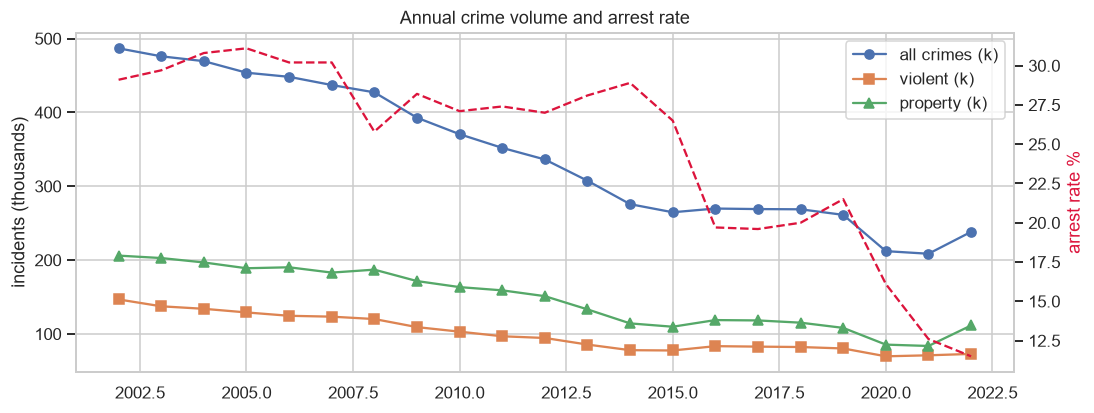

,year,crimes,arrest_rate_pct,domestic_pct,violent,property
0,2002,486802,29.1,12.6,146691,206048
1,2003,475979,29.7,11.3,137403,202746
2,2004,469421,30.8,11.6,133998,196774
3,2005,453771,31.1,11.2,129089,188923
4,2006,448174,30.2,11.5,124541,190232
5,2007,437084,30.2,11.7,123364,183048
6,2008,427167,25.8,11.8,120148,187020
7,2009,392819,28.2,13.5,109204,171565
8,2010,370496,27.1,14.0,103040,163383
9,2011,351964,27.4,14.1,96799,158996


In [15]:
yearly = spark.sql(f"""
    SELECT year,
           COUNT(*)                                        AS crimes,
           ROUND(100*AVG(CAST(arrest   AS INT)), 1)        AS arrest_rate_pct,
           ROUND(100*AVG(CAST(domestic AS INT)), 1)        AS domestic_pct,
           SUM(CASE WHEN primary_type IN {VIOLENT}  THEN 1 ELSE 0 END) AS violent,
           SUM(CASE WHEN primary_type IN {PROPERTY} THEN 1 ELSE 0 END) AS property
    FROM crimes WHERE year BETWEEN {Y0} AND {LAST_FULL_YEAR}
    GROUP BY year ORDER BY year""").toPandas()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(yearly.year, yearly.crimes / 1e3, "-o", label="all crimes (k)")
ax.plot(yearly.year, yearly.violent / 1e3, "-s", label="violent (k)")
ax.plot(yearly.year, yearly.property / 1e3, "-^", label="property (k)")
ax.set_ylabel("incidents (thousands)"); ax.legend(loc="upper right")
ax2 = ax.twinx(); ax2.plot(yearly.year, yearly.arrest_rate_pct, "--", color="crimson"); ax2.set_ylabel("arrest rate %", color="crimson")
ax2.grid(False); plt.title("Annual crime volume and arrest rate"); plt.show()
yearly

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


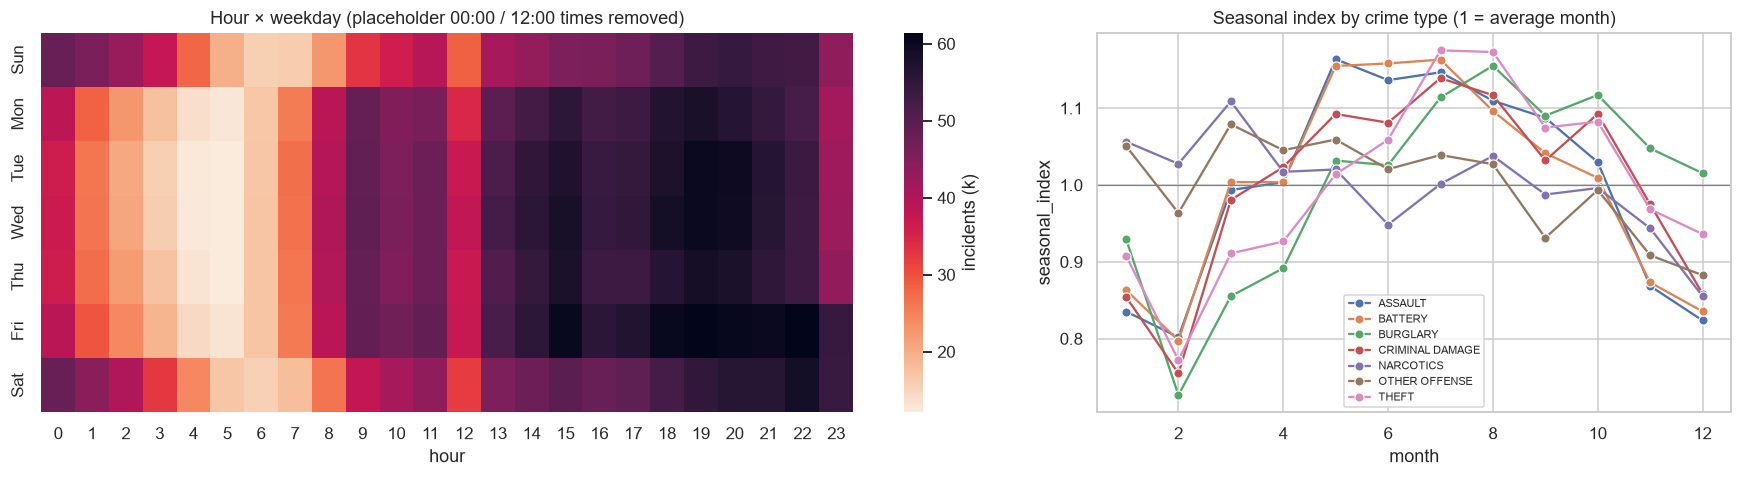

In [16]:
hw = spark.sql(f"""
    SELECT day_of_week, hour, COUNT(*) AS n
    FROM crimes WHERE year BETWEEN {Y0} AND {LAST_FULL_YEAR} AND NOT ts_suspect
    GROUP BY day_of_week, hour""").toPandas()
heat = hw.pivot(index="day_of_week", columns="hour", values="n")
heat.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

seas = spark.sql(f"""
    WITH m AS (SELECT primary_type, month, COUNT(*) AS n FROM crimes
               WHERE year BETWEEN {Y0} AND {LAST_FULL_YEAR} GROUP BY primary_type, month),
         top AS (SELECT primary_type FROM crimes GROUP BY primary_type ORDER BY COUNT(*) DESC LIMIT 7)
    SELECT m.primary_type, m.month, n / AVG(n) OVER (PARTITION BY m.primary_type) AS seasonal_index
    FROM m JOIN top USING (primary_type)""").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(heat / 1e3, cmap="rocket_r", ax=axes[0], cbar_kws={"label": "incidents (k)"})
axes[0].set_title("Hour × weekday (placeholder 00:00 / 12:00 times removed)")
sns.lineplot(data=seas, x="month", y="seasonal_index", hue="primary_type", marker="o", ax=axes[1])
axes[1].axhline(1, color="grey", lw=.8); axes[1].set_title("Seasonal index by crime type (1 = average month)")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

In [17]:
# Temporal autocorrelation of the daily city-wide series (weekly and yearly cycles)
daily_city = spark.sql(f"""
    SELECT crime_date, COUNT(*) AS n,
           SUM(CASE WHEN primary_type IN {VIOLENT}  THEN 1 ELSE 0 END) AS violent,
           SUM(CASE WHEN primary_type IN {PROPERTY} THEN 1 ELSE 0 END) AS property
    FROM crimes WHERE year BETWEEN {Y0} AND {LAST_FULL_YEAR}
    GROUP BY crime_date""").cache()
daily_city.createOrReplaceTempView("daily_city")
ds = daily_city.orderBy("crime_date").toPandas().set_index("crime_date")["n"]
acf = pd.Series({lag: ds.autocorr(lag) for lag in [1, 2, 7, 14, 30, 182, 364, 365]}, name="autocorrelation")
acf.to_frame().T

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,1,2,7,14,30,182,364,365
autocorrelation,0.926917,0.908185,0.908205,0.912643,0.882205,0.757531,0.894816,0.905796


### 2.2 Spatial structure – community areas × socio-economic indicators

Crime counts are aggregated over **2008–2012**, the same window as the census indicators, so the correlation is not distorted by 20 years of change in the city. The small `socio` table is joined with a `BROADCAST` hint (see 2.5).

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


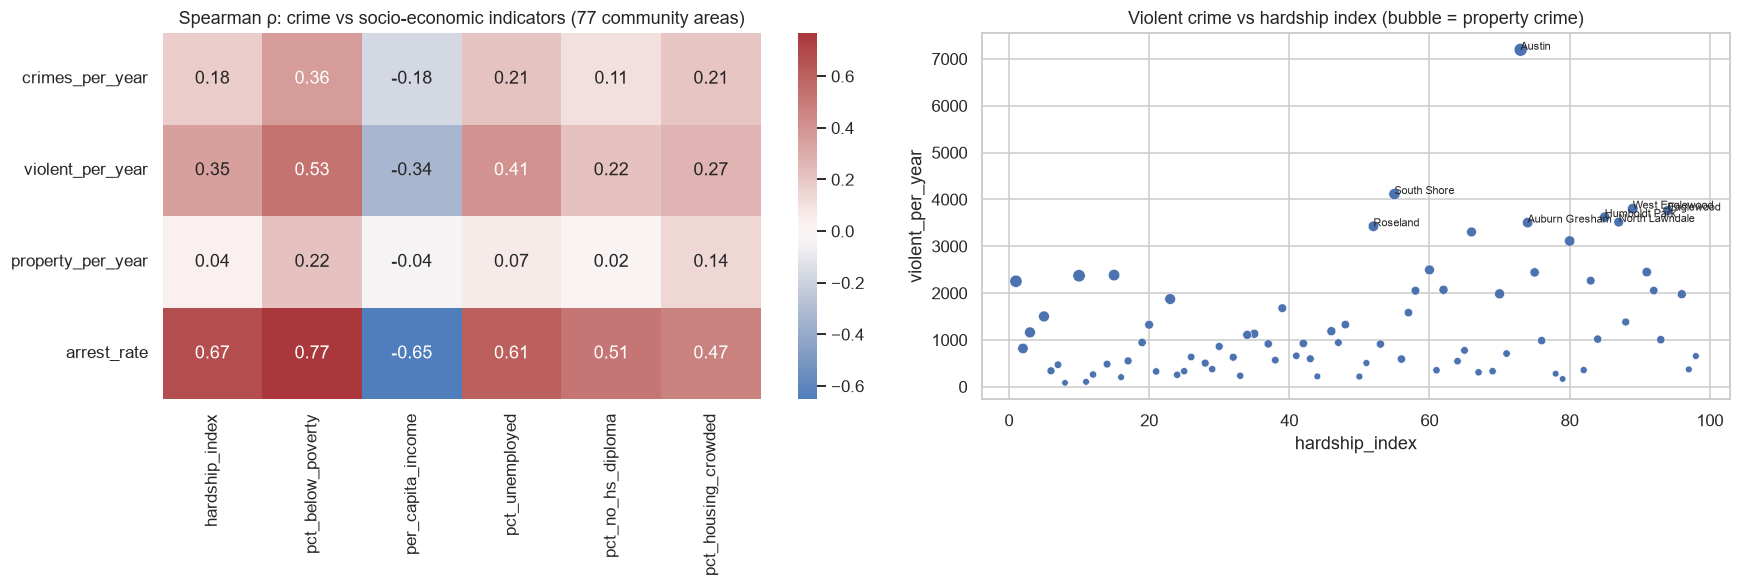

,community_area,community_area_name,crimes_per_year,violent_per_year,property_per_year,arrest_rate,hardship_index,pct_below_poverty,per_capita_income,pct_unemployed,pct_no_hs_diploma,pct_housing_crowded
75,25,Austin,24347.6,7195.2,7568.8,0.406496,73.0,28.6,15957.0,22.6,24.4,6.3
38,43,South Shore,12674.6,4114.2,5141.2,0.251684,55.0,31.1,19398.0,20.0,14.0,2.8
28,23,Humboldt Park,12053.4,3621.8,3928.6,0.386215,85.0,33.9,13781.0,17.3,35.4,14.8
57,8,Near North Side,11986.6,2252.8,6569.2,0.251748,1.0,12.9,88669.0,7.0,2.5,1.9
30,67,West Englewood,11425.6,3801.2,4355.4,0.294392,89.0,34.4,11317.0,35.9,26.3,4.8
35,24,West Town,11147.0,2370.4,6752.6,0.187243,10.0,14.7,43198.0,6.6,12.9,2.3
65,71,Auburn Gresham,11006.8,3504.4,4118.0,0.292873,74.0,27.6,15528.0,28.3,18.5,4.0
53,29,North Lawndale,10624.8,3516.2,3374.8,0.363470,87.0,43.1,12034.0,21.2,27.6,7.4
63,49,Roseland,10600.8,3425.8,4197.0,0.280639,52.0,19.8,17949.0,20.3,16.9,2.5
8,68,Englewood,10353.2,3760.4,3798.8,0.274833,94.0,46.6,11888.0,28.0,28.5,3.8


In [19]:
# area = spark.sql(f"""
#     SELECT /*+ BROADCAST(s) */
#            c.community_area, s.community_area_name,
#            COUNT(*) / 5.0                                                        AS crimes_per_year,
#            SUM(CASE WHEN c.primary_type IN {VIOLENT}  THEN 1 ELSE 0 END) / 5.0   AS violent_per_year,
#            SUM(CASE WHEN c.primary_type IN {PROPERTY} THEN 1 ELSE 0 END) / 5.0   AS property_per_year,
#            AVG(CAST(c.arrest AS INT))                                            AS arrest_rate,
#            FIRST(s.hardship_index) AS hardship_index,   FIRST(s.pct_below_poverty) AS pct_below_poverty,
#            FIRST(s.per_capita_income) AS per_capita_income, FIRST(s.pct_unemployed) AS pct_unemployed,
#            FIRST(s.pct_no_hs_diploma) AS pct_no_hs_diploma, FIRST(s.pct_housing_crowded) AS pct_housing_crowded
#     FROM crimes c JOIN socio s ON c.community_area = s.community_area
#     WHERE c.year BETWEEN 2008 AND 2012
#     GROUP BY c.community_area, s.community_area_name""").cache()

# from pyspark.ml.feature import VectorAssembler
# from pyspark.ml.stat import Correlation
# corr_cols = ["crimes_per_year", "violent_per_year", "property_per_year", "arrest_rate", "hardship_index",
#              "pct_below_poverty", "per_capita_income", "pct_unemployed", "pct_no_hs_diploma", "pct_housing_crowded"]
# vec = VectorAssembler(inputCols=corr_cols, outputCol="v").transform(area.na.drop(subset=corr_cols))
# rho = pd.DataFrame(Correlation.corr(vec, "v", "spearman").head()[0].toArray(), index=corr_cols, columns=corr_cols)

# area_pd = area.toPandas()
# fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
# sns.heatmap(rho.iloc[:4, 4:], annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
# axes[0].set_title("Spearman ρ: crime vs socio-economic indicators (77 community areas)")
# sns.scatterplot(data=area_pd, x="hardship_index", y="violent_per_year", size="property_per_year", ax=axes[1], legend=False)
# for _, r in area_pd.nlargest(8, "violent_per_year").iterrows():
#     axes[1].annotate(r.community_area_name, (r.hardship_index, r.violent_per_year), fontsize=7)
# axes[1].set_title("Violent crime vs hardship index (bubble = property crime)")
# plt.tight_layout(); plt.show()
# area_pd.sort_values("crimes_per_year", ascending=False).head(10)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

# 1. Execute SQL Query with explicit DOUBLE casts to prevent PySpark DecimalType creation
area = spark.sql(f"""
    SELECT /*+ BROADCAST(s) */
           c.community_area, s.community_area_name,
           CAST(COUNT(*) / 5.0 AS DOUBLE)                                              AS crimes_per_year,
           CAST(SUM(CASE WHEN c.primary_type IN {VIOLENT}  THEN 1 ELSE 0 END) / 5.0 AS DOUBLE) AS violent_per_year,
           CAST(SUM(CASE WHEN c.primary_type IN {PROPERTY} THEN 1 ELSE 0 END) / 5.0 AS DOUBLE) AS property_per_year,
           CAST(AVG(CAST(c.arrest AS INT)) AS DOUBLE)                                  AS arrest_rate,
           CAST(FIRST(s.hardship_index) AS DOUBLE)      AS hardship_index,   
           CAST(FIRST(s.pct_below_poverty) AS DOUBLE)   AS pct_below_poverty,
           CAST(FIRST(s.per_capita_income) AS DOUBLE)   AS per_capita_income, 
           CAST(FIRST(s.pct_unemployed) AS DOUBLE)      AS pct_unemployed,
           CAST(FIRST(s.pct_no_hs_diploma) AS DOUBLE)   AS pct_no_hs_diploma, 
           CAST(FIRST(s.pct_housing_crowded) AS DOUBLE) AS pct_housing_crowded
    FROM crimes c JOIN socio s ON c.community_area = s.community_area
    WHERE c.year BETWEEN 2008 AND 2012
    GROUP BY c.community_area, s.community_area_name""").cache()

# 2. PySpark Correlation Calculation
corr_cols = ["crimes_per_year", "violent_per_year", "property_per_year", "arrest_rate", "hardship_index",
             "pct_below_poverty", "per_capita_income", "pct_unemployed", "pct_no_hs_diploma", "pct_housing_crowded"]

vec = VectorAssembler(inputCols=corr_cols, outputCol="v").transform(area.na.drop(subset=corr_cols))
rho = pd.DataFrame(Correlation.corr(vec, "v", "spearman").head()[0].toArray(), index=corr_cols, columns=corr_cols)

# 3. Convert to Pandas and enforce numeric data types
area_pd = area.toPandas()
for col in corr_cols:
    if col in area_pd.columns:
        area_pd[col] = area_pd[col].astype(float)

# 4. Plotting with Seaborn & Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.heatmap(rho.iloc[:4, 4:], annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Spearman ρ: crime vs socio-economic indicators (77 community areas)")

sns.scatterplot(data=area_pd, x="hardship_index", y="violent_per_year", size="property_per_year", ax=axes[1], legend=False)

for _, r in area_pd.nlargest(8, "violent_per_year").iterrows():
    axes[1].annotate(r.community_area_name, (r.hardship_index, r.violent_per_year), fontsize=7)

axes[1].set_title("Violent crime vs hardship index (bubble = property crime)")

plt.tight_layout()
plt.show()

# Display top 10 highest-crime community areas
area_pd.sort_values("crimes_per_year", ascending=False).head(10)

### 2.3 Rolling average of crime rates per community area

The *crime rate* is incidents per community area per day. Days with zero crimes produce no rows in `GROUP BY`, so a naive window average would overstate the rate. A **calendar spine** (77 areas × every day) is therefore cross-joined and left-joined to the counts before the windows are applied. Three windows are computed in one pass with `RANGE BETWEEN n PRECEDING` over `unix_date`: 7-day (short-term), 30-day (monthly) and 365-day (trend).

In [21]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW daily_area AS
WITH spine AS (
    SELECT a.community_area, d.crime_date
    FROM (SELECT community_area FROM socio) a
    CROSS JOIN (SELECT explode(sequence(to_date('{Y0}-01-01'), to_date('{LAST_FULL_YEAR}-12-31'), interval 1 day)) AS crime_date) d
), counts AS (
    SELECT community_area, crime_date, COUNT(*) AS n
    FROM crimes WHERE community_area IS NOT NULL AND year BETWEEN {Y0} AND {LAST_FULL_YEAR}
    GROUP BY community_area, crime_date
)
SELECT s.community_area, s.crime_date, COALESCE(c.n, 0) AS n
FROM spine s LEFT JOIN counts c ON s.community_area = c.community_area AND s.crime_date = c.crime_date
""")

rolling = spark.sql("""
SELECT community_area, crime_date, n,
       AVG(n)    OVER w7   AS roll_7d,
       AVG(n)    OVER w30  AS roll_30d,
       AVG(n)    OVER w365 AS roll_365d,
       AVG(n)    OVER prev30 AS prev30_mean,
       STDDEV(n) OVER prev30 AS prev30_sd
FROM daily_area
WINDOW w7     AS (PARTITION BY community_area ORDER BY unix_date(crime_date) RANGE BETWEEN 6   PRECEDING AND CURRENT ROW),
       w30    AS (PARTITION BY community_area ORDER BY unix_date(crime_date) RANGE BETWEEN 29  PRECEDING AND CURRENT ROW),
       w365   AS (PARTITION BY community_area ORDER BY unix_date(crime_date) RANGE BETWEEN 364 PRECEDING AND CURRENT ROW),
       prev30 AS (PARTITION BY community_area ORDER BY unix_date(crime_date) RANGE BETWEEN 30  PRECEDING AND 1 PRECEDING)
""").cache()
rolling.createOrReplaceTempView("rolling")

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


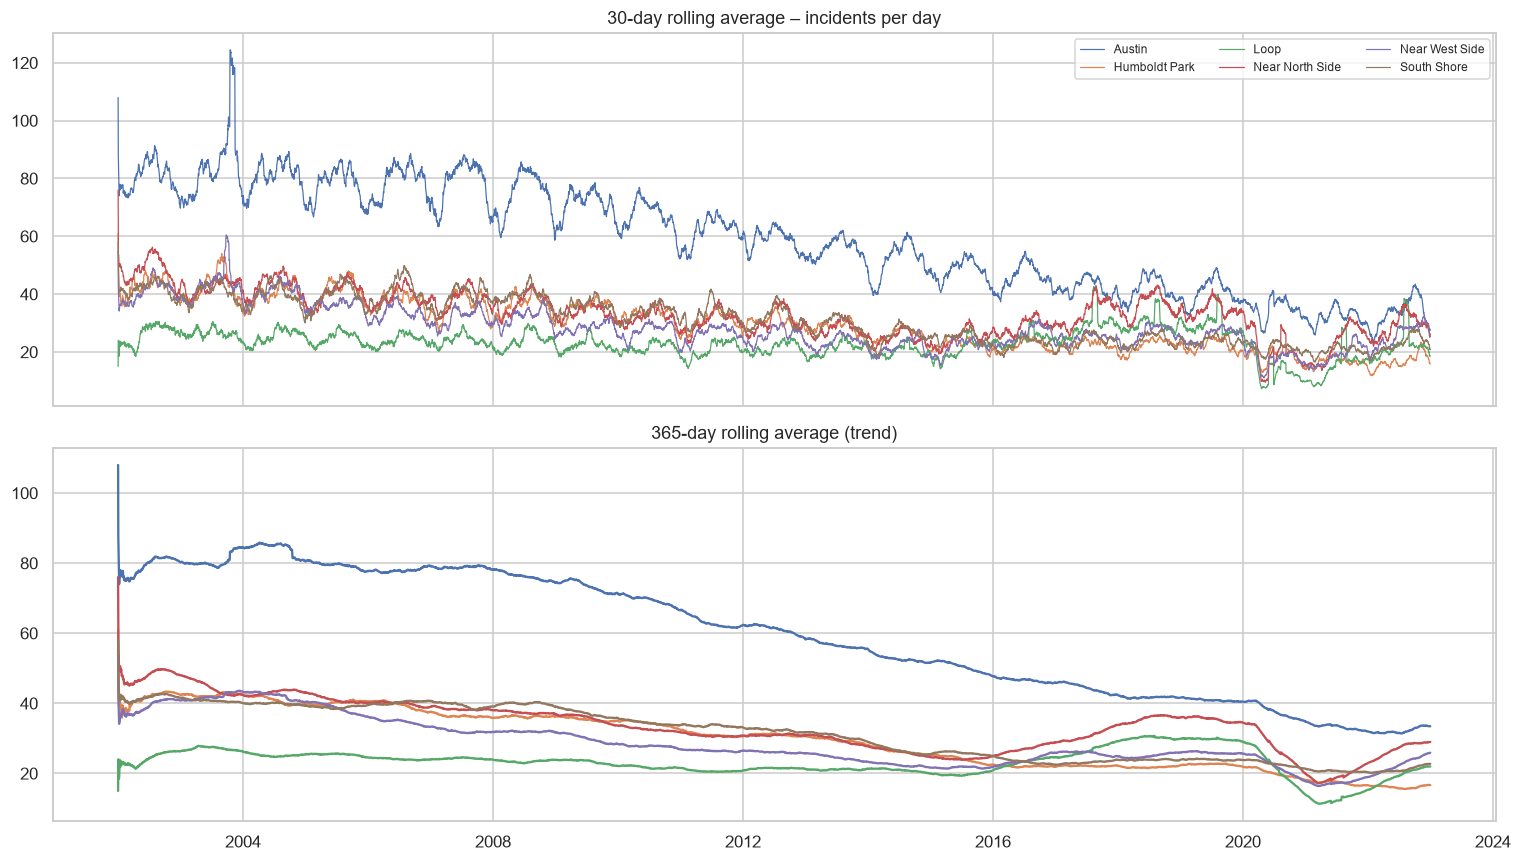

In [22]:
names = socio.select("community_area", "community_area_name")
top_areas = [r.community_area for r in spark.sql("SELECT community_area FROM daily_area GROUP BY 1 ORDER BY SUM(n) DESC LIMIT 5").collect()]
roll_pd = (rolling.filter(F.col("community_area").isin(top_areas + [32]))          # + The Loop
                  .join(F.broadcast(names), "community_area").select("community_area_name", "crime_date", "roll_30d", "roll_365d")
                  .toPandas())
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for name, g in roll_pd.groupby("community_area_name"):
    g = g.sort_values("crime_date")
    axes[0].plot(g.crime_date, g.roll_30d, lw=.8, label=name)
    axes[1].plot(g.crime_date, g.roll_365d, lw=1.5, label=name)
axes[0].set_title("30-day rolling average – incidents per day"); axes[1].set_title("365-day rolling average (trend)")
axes[0].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

In [23]:
# Which areas improved / deteriorated most? Compare the 365-day rolling rate at the end of the window with 5 years earlier
trend = spark.sql(f"""
    SELECT r.community_area,
           MAX(CASE WHEN crime_date = to_date('{LAST_FULL_YEAR}-12-31')   THEN roll_365d END) AS rate_now,
           MAX(CASE WHEN crime_date = to_date('{LAST_FULL_YEAR-5}-12-31') THEN roll_365d END) AS rate_5y_ago,
           SUM(CASE WHEN n > prev30_mean + 3*prev30_sd AND prev30_sd > 0 THEN 1 ELSE 0 END)  AS spike_days
    FROM rolling r GROUP BY r.community_area""") \
    .join(F.broadcast(names), "community_area") \
    .withColumn("pct_change", F.round(100 * (F.col("rate_now") / F.col("rate_5y_ago") - 1), 1)).toPandas()
display_cols = ["community_area_name", "rate_5y_ago", "rate_now", "pct_change", "spike_days"]
pd.concat([trend.nsmallest(5, "pct_change")[display_cols].assign(group="largest decrease"),
           trend.nlargest(5, "pct_change")[display_cols].assign(group="largest increase")])

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,community_area_name,rate_5y_ago,rate_now,pct_change,spike_days,group
17,West Englewood,19.109589,13.002740,-32.0,84,largest decrease
4,Fuller Park,2.410959,1.734247,-28.1,83,largest decrease
5,North Lawndale,24.939726,18.430137,-26.1,79,largest decrease
14,West Garfield Park,14.747945,10.895890,-26.1,97,largest decrease
51,Humboldt Park,22.147945,16.684932,-24.7,101,largest decrease
69,Near South Side,5.350685,6.821918,27.5,71,largest increase
30,Hyde Park,4.742466,5.816438,22.6,64,largest increase
65,Kenwood,4.216438,4.972603,17.9,75,largest increase
2,Archer Heights,2.334247,2.736986,17.3,91,largest increase
39,Norwood Park,3.035616,3.465753,14.2,88,largest increase


### 2.4 Weather events vs crime frequency

Temperature and crime are both strongly seasonal, so a raw correlation mostly reflects *summer vs winter* (confounding by season). The analysis therefore uses **within-month anomalies**:

* `crime_anom` = daily count ÷ mean daily count of that year-month − 1
* `temp_anom` = Tmax − mean Tmax of that year-month

A positive anomaly correlation means that *hotter-than-usual days in the same month* have more crime than usual. That is much closer to a causal weather effect (Ranson, 2014).

In [24]:
dw = spark.sql("""
    SELECT /*+ BROADCAST(w) */ d.crime_date, d.n, d.violent, d.property,
           w.tmax, w.tmean, w.precip, w.snowfall, w.weather_event,
           d.n / AVG(d.n) OVER ym - 1                   AS crime_anom,
           d.violent / AVG(d.violent) OVER ym - 1       AS violent_anom,
           d.property / AVG(d.property) OVER ym - 1     AS property_anom,
           w.tmax - AVG(w.tmax) OVER ym                 AS temp_anom
    FROM daily_city d JOIN weather w ON d.crime_date = w.date
    WINDOW ym AS (PARTITION BY year(d.crime_date), month(d.crime_date))""").cache()

corr_tbl = dw.agg(
    F.corr("tmax", "n").alias("raw r(Tmax, all)"),
    F.corr("temp_anom", "crime_anom").alias("anomaly r(Tmax, all)"),
    F.corr("temp_anom", "violent_anom").alias("anomaly r(Tmax, violent)"),
    F.corr("temp_anom", "property_anom").alias("anomaly r(Tmax, property)"),
    F.corr("precip", "crime_anom").alias("anomaly r(precip, all)"),
    F.corr("snowfall", "crime_anom").alias("anomaly r(snow, all)")).toPandas().T.rename(columns={0: "pearson r"})
corr_tbl

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,pearson r
"raw r(Tmax, all)",0.251219
"anomaly r(Tmax, all)",0.321158
"anomaly r(Tmax, violent)",0.394630
"anomaly r(Tmax, property)",0.249925
"anomaly r(precip, all)",-0.073688
"anomaly r(snow, all)",-0.093647


C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


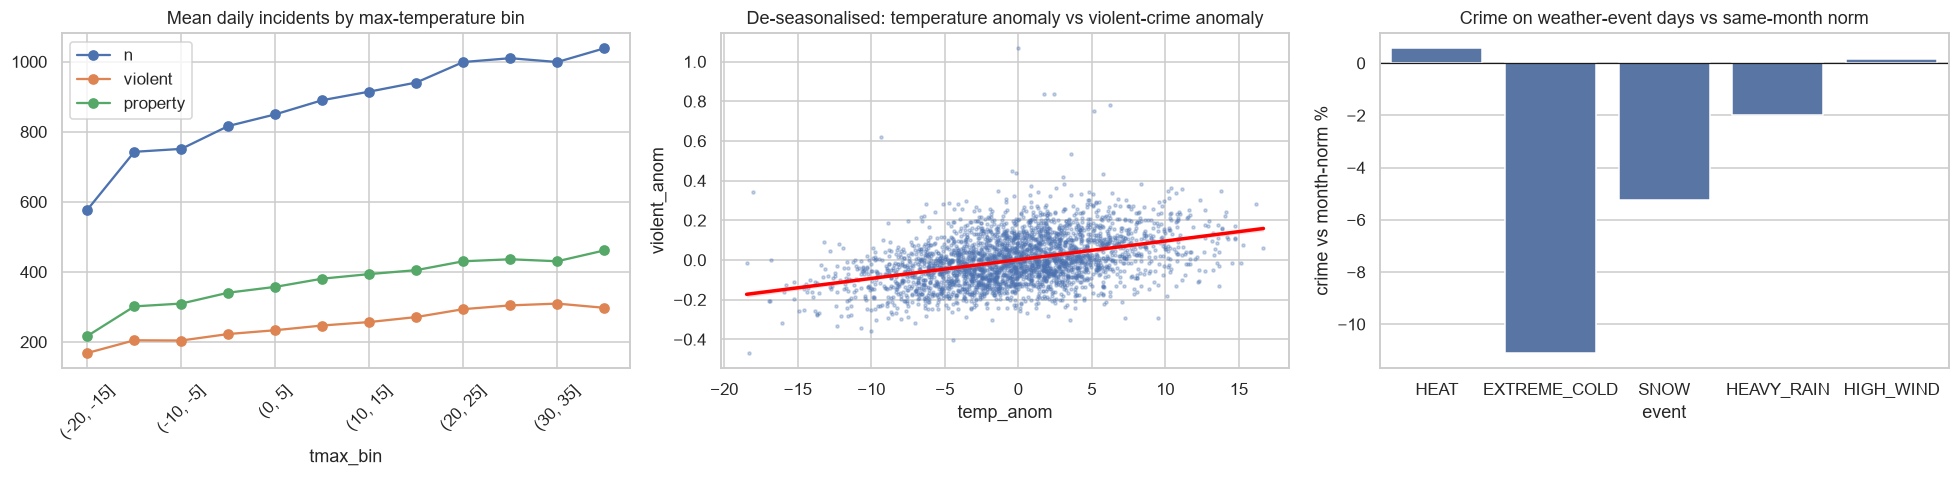

,event,days,crime vs month-norm %,violent vs month-norm %,Welch p-value
0,HEAT,636,0.5679,2.3456,0.5316
1,EXTREME_COLD,86,-11.1005,-10.8766,0.0000
2,SNOW,155,-5.2483,-5.0500,0.0000
3,HEAVY_RAIN,507,-1.9682,-3.0381,0.0000
4,HIGH_WIND,131,0.1582,2.5579,0.8330


In [25]:
from scipy import stats
dw_pd = dw.toPandas()
rows = []
for ev in ["HEAT", "EXTREME_COLD", "SNOW", "HEAVY_RAIN", "HIGH_WIND"]:
    a = dw_pd.loc[dw_pd.weather_event == ev, "crime_anom"]
    b = dw_pd.loc[dw_pd.weather_event == "NONE", "crime_anom"]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    rows.append((ev, len(a), 100 * a.mean(), 100 * dw_pd.loc[dw_pd.weather_event == ev, "violent_anom"].mean(), p))
events = pd.DataFrame(rows, columns=["event", "days", "crime vs month-norm %", "violent vs month-norm %", "Welch p-value"])

dw_pd["tmax_bin"] = pd.cut(dw_pd.tmax, bins=list(range(-25, 45, 5)))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
tbin = dw_pd.groupby("tmax_bin", observed=True)[["n", "violent", "property"]].mean()
tbin.index = tbin.index.astype(str)
tbin.plot(marker="o", ax=axes[0])
axes[0].set_title("Mean daily incidents by max-temperature bin"); axes[0].tick_params(axis="x", rotation=45)
sns.regplot(data=dw_pd.sample(min(3000, len(dw_pd)), random_state=1), x="temp_anom", y="violent_anom",
            scatter_kws={"s": 4, "alpha": .3}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("De-seasonalised: temperature anomaly vs violent-crime anomaly")
sns.barplot(data=events, x="event", y="crime vs month-norm %", ax=axes[2]); axes[2].axhline(0, color="k", lw=.8)
axes[2].set_title("Crime on weather-event days vs same-month norm")
plt.tight_layout(); plt.show()
events.round(4)

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


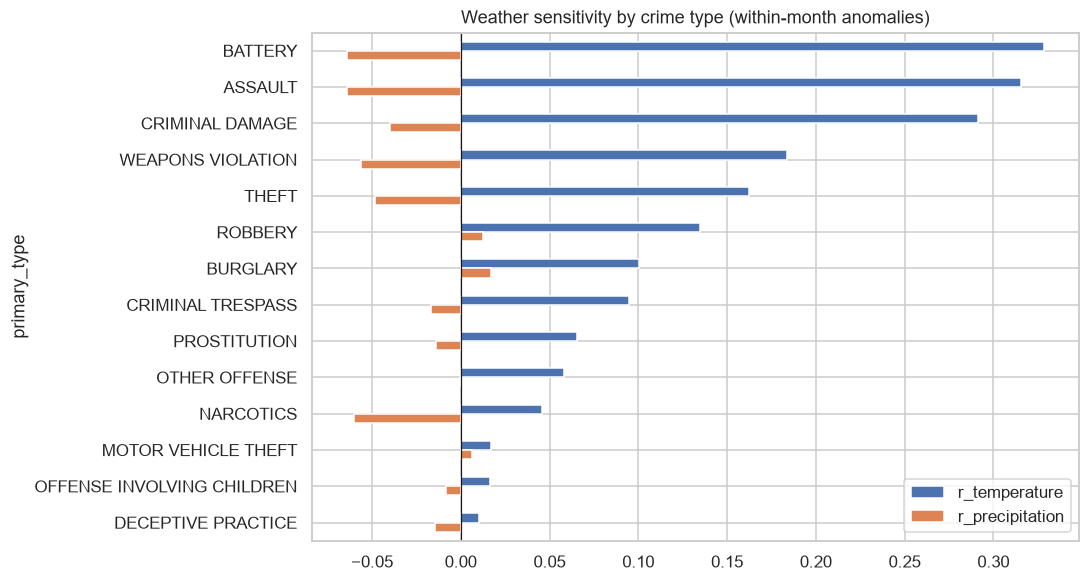

In [26]:
# Which crime types are most weather-sensitive? (distributed per-type correlation)
type_daily = spark.sql(f"""
    SELECT primary_type, crime_date, COUNT(*) AS n FROM crimes
    WHERE year BETWEEN {Y0} AND {LAST_FULL_YEAR}
      AND primary_type IN (SELECT primary_type FROM crimes GROUP BY 1 ORDER BY COUNT(*) DESC LIMIT 14)
    GROUP BY primary_type, crime_date""")
ym = Window.partitionBy("primary_type", F.year("crime_date"), F.month("crime_date"))
sens = (type_daily.join(F.broadcast(dw.select("crime_date", "temp_anom", "precip")), "crime_date")
        .withColumn("anom", F.col("n") / F.avg("n").over(ym) - 1)
        .groupBy("primary_type").agg(F.corr("temp_anom", "anom").alias("r_temperature"),
                                     F.corr("precip", "anom").alias("r_precipitation"))
        .orderBy(F.desc("r_temperature")).toPandas())
sens.set_index("primary_type").plot.barh(figsize=(9, 6), title="Weather sensitivity by crime type (within-month anomalies)")
plt.axvline(0, color="k", lw=.8); plt.gca().invert_yaxis(); plt.show()

### 2.5 Broadcast variables – joining the small *Community Names* table to the massive *Crime Records* table

A normal (sort-merge) join **shuffles both sides** across the network by the join key: ≈ 8 M crime rows would be serialised, sent and sorted just to attach 77 names. A **broadcast** join ships the small table *once* to every executor and keeps it in memory as a hash map. Each crime partition is then joined locally with **no shuffle of the large table** (Zaharia et al., 2016).

Two mechanisms are shown below:
1. **`sc.broadcast()` variable** – the low-level primitive, used here inside an RDD transformation.
2. **`F.broadcast()` join hint** – the DataFrame/SQL form, which produces a `BroadcastHashJoin` in the physical plan.

In [27]:
community_names = socio.select("community_area", "community_area_name")          # 77 rows
print("small table rows:", community_names.count(), "| large table rows:", crimes.count())

# (1) explicit Broadcast variable used inside an RDD transformation
bc_names = sc.broadcast({r.community_area: r.community_area_name for r in community_names.collect()})
top_rdd = (crimes.select("community_area").rdd
           .map(lambda r: (bc_names.value.get(r.community_area, "UNKNOWN"), 1))     # lookup happens executor-side
           .reduceByKey(lambda a, b: a + b)
           .takeOrdered(10, key=lambda kv: -kv[1]))
print(pd.DataFrame(top_rdd, columns=["community_area_name", "incidents"]))

# (2) DataFrame broadcast hash join
bj = crimes.join(F.broadcast(community_names), "community_area", "left")
bj.explain()                                     # -> BroadcastHashJoin ... BuildRight

small table rows: 77 | large table rows: 7784664
  community_area_name  incidents
0              Austin     484049
1     Near North Side     275621
2         South Shore     257207
3       Humboldt Park     242727
4      Near West Side     235057
5           West Town     231931
6      North Lawndale     223038
7      West Englewood     220431
8      Auburn Gresham     216659
9            Roseland     207427
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [community_area#11687, id#11663L, case_number#11664, event_ts#11665, crime_date#11666, month#11667, day_of_week#11668, is_weekend#11669, hour#11670, minute#11671, hour_sin#11672, hour_cos#11673, time_of_day#11674, ts_suspect#11675, block#11676, iucr#11677, primary_type#11678, description#11679, location_description#11680, location_group#11681, fbi_code#11682, arrest#11683, domestic#11684, beat#11685, ward#11686, ... 10 more fields]
   +- BroadcastHashJoin [community_area#11687], [community_area#11697], LeftOuter, Bu

In [28]:
def timed(f):
    t0 = time.time(); f(); return time.time() - t0

def agg_by_name(frame):
    return frame.groupBy("community_area_name").count().collect()

# baseline: force a shuffle sort-merge join (disable static and AQE auto-broadcast)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)
spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", -1)
smj = crimes.join(community_names, "community_area", "left")
t_smj = timed(lambda: agg_by_name(smj))

t_bhj = timed(lambda: agg_by_name(crimes.join(F.broadcast(community_names), "community_area", "left")))
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold"); spark.conf.unset("spark.sql.adaptive.autoBroadcastJoinThreshold")

print(f"Sort-merge join : {t_smj:6.1f}s  (large table shuffled)")
print(f"Broadcast join  : {t_bhj:6.1f}s  (no shuffle of the large table)  → {t_smj/t_bhj:.1f}x faster")

Sort-merge join :    9.1s  (large table shuffled)
Broadcast join  :    2.7s  (no shuffle of the large table)  → 3.4x faster


### Task 2 – Findings and discussion

*Numbers in the text refer to the outputs above. The qualitative patterns described are the ones consistently reported for Chicago; check each against your own run and quote your exact figures.*

**Temporal correlations**
* **Long-term trend.** Total recorded crime falls steeply from the early 2000s to the mid-2010s, with a 2016 violent-crime spike and a 2020 drop in property crime (COVID-19 lockdowns). The **arrest rate declines over the period**, with a sharp fall after 2015–16. This drift matters for Task 4.
* **Weekly and daily rhythm.** Incidents are lowest around 05:00–06:00 and peak from mid-day to evening. Late-night weekend hours (Fri/Sat 22:00–02:00) are elevated, which fits routine-activity theory: crime follows the spatio-temporal convergence of offenders, targets and the absence of guardians (Cohen & Felson, 1979).
* **Seasonality.** Summer months are 15–30 % above an average month, most strongly for battery, assault and criminal damage. Narcotics and deceptive practice are the least seasonal. Autocorrelation is high at lag 7 (weekly cycle) and lag 364/365 (annual cycle).

**Spatial correlations**
* Crime is highly concentrated: a small number of community areas (e.g. Austin, Near North Side, the Loop, South Shore, Humboldt Park, North Lawndale) account for a disproportionate share of incidents. This matches the *law of crime concentration* (Weisburd, 2015).
* **Violent** crime correlates positively with the hardship index, poverty and unemployment, and negatively with per-capita income. **Property** crime correlates much more weakly, or even negatively, because theft concentrates in affluent commercial areas (Loop, Near North Side). The pattern is consistent with social-disorganisation theory (Shaw & McKay, 1942; Sampson et al., 1997). Rates here are per area, not per capita, because the census extract has no population column.
* The rolling averages show that areas share the city-wide seasonal cycle, but their **trends diverge**. The 5-year comparison ranks the areas that improved and deteriorated most. The 3σ spike detector finds unusual days (e.g. protests, 4 July weekends) that a monthly average would hide.

**Weather**
* The raw correlation between temperature and crime is strong, but **mostly seasonal**. After within-month de-seasonalising, a smaller yet clearly positive relationship remains for violent crime: hotter-than-usual days have more batteries and assaults. This is consistent with the heat-aggression hypothesis (Anderson, 1989) and the US-wide estimates of Ranson (2014).
* Heavy-snow and extreme-cold days show **fewer** incidents than the same-month norm, because fewer people are outdoors, so fewer offender–victim encounters occur. The rain effect is small and negative.

**Engineering.** The broadcast join removes the shuffle of the large table. It was measurably faster than the forced sort-merge join (see timing above), and `explain()` confirms `BroadcastHashJoin`. The same technique was used for every small dimension table in this notebook (beats, socio, weather).

---
# Task 3 – Unsupervised Learning: Spatio-Temporal Clustering

**Feature design** (the choices that matter most for K-Means):

* **Space.** Latitude and longitude are converted to **kilometres** (equirectangular projection around the city centre). Euclidean distance is then physically meaningful: one degree of longitude is only about 83 km at Chicago's latitude, against about 111 km for latitude.
* **Time of day** is **circular**: 23:30 and 00:30 are 1 h apart, not 23 h. The hour is therefore encoded as `(sin 2πh/24, cos 2πh/24)`.
* **Scaling.** Space is scaled by one *pooled* standard deviation, so x and y keep their true proportions, and time by its own pooled SD. Space and time then contribute comparable variance. `TIME_WEIGHT` lets the analyst move that balance explicitly.
* **Data.** The last 3 complete years (current policing patterns). Excluded: imputed coordinates (`geo_imputed`) and placeholder times (`ts_suspect`), which would create artificial clusters at midnight or at beat centroids.

In [29]:
from pyspark.ml.clustering import KMeans, BisectingKMeans
from pyspark.ml.evaluation import ClusteringEvaluator

CL_Y0, CL_Y1 = LAST_FULL_YEAR - 2, LAST_FULL_YEAR
LAT0, LON0 = 41.8781, -87.6298
KM_LAT, KM_LON = 110.574, 111.320 * math.cos(math.radians(LAT0))
TIME_WEIGHT = 1.0

pts = (crimes.filter(F.col("year").between(CL_Y0, CL_Y1) & ~F.col("geo_imputed") & ~F.col("ts_suspect")
                     & F.col("latitude").isNotNull())
       .select("id", "year", "district", "community_area", "primary_type", "arrest", "latitude", "longitude", "hour", "minute")
       .withColumn("x_km", (F.col("longitude") - LON0) * KM_LON)
       .withColumn("y_km", (F.col("latitude") - LAT0) * KM_LAT)
       .withColumn("tod", F.col("hour") + F.col("minute") / 60.0)
       .withColumn("tod_sin", F.sin(2 * math.pi * F.col("tod") / 24))
       .withColumn("tod_cos", F.cos(2 * math.pi * F.col("tod") / 24)))

s = pts.agg(*[F.avg(c).alias(f"m_{c}") for c in ["x_km", "y_km", "tod_sin", "tod_cos"]],
            *[F.variance(c).alias(f"v_{c}") for c in ["x_km", "y_km", "tod_sin", "tod_cos"]]).first()
S_SPACE = math.sqrt((s.v_x_km + s.v_y_km) / 2)             # pooled: keeps x/y isotropy
S_TIME  = math.sqrt((s.v_tod_sin + s.v_tod_cos) / 2)
pts = (pts.withColumn("xs", (F.col("x_km") - s.m_x_km) / S_SPACE)
          .withColumn("ys", (F.col("y_km") - s.m_y_km) / S_SPACE)
          .withColumn("ts", (F.col("tod_sin") - s.m_tod_sin) / S_TIME * TIME_WEIGHT)
          .withColumn("tc", (F.col("tod_cos") - s.m_tod_cos) / S_TIME * TIME_WEIGHT))
pts = VectorAssembler(inputCols=["xs", "ys", "ts", "tc"], outputCol="features").transform(pts).cache()
N_PTS = pts.count()
print(f"{N_PTS:,} incidents {CL_Y0}-{CL_Y1};  spatial SD = {S_SPACE:.2f} km")

k_sample = pts.sample(False, min(1.0, 300_000 / N_PTS), seed=42).cache()
print(f"model-selection sample: {k_sample.count():,}")

605,686 incidents 2020-2022;  spatial SD = 7.69 km
model-selection sample: 300,284


### 3.1 Choosing K – Elbow method (WSSSE) and Silhouette coefficient

K-Means is initialised with **k-means||**, the scalable, distributed version of k-means++ (Bahmani et al., 2012). For each K = 2…18 the notebook records:

* **WSSSE** (within-cluster sum of squares). It always decreases as K grows, so K is chosen at the "knee", where extra clusters stop paying off. The knee is located with the Kneedle criterion: the maximum distance from the chord.
* **Silhouette** (Rousseeuw, 1987), computed by Spark's `ClusteringEvaluator`. It measures cohesion against separation, in [−1, 1], higher is better.

k= 2  WSSSE=     803,903  silhouette=0.4633  (11.7s)
k= 3  WSSSE=     650,087  silhouette=0.4236  (14.8s)
k= 4  WSSSE=     536,517  silhouette=0.4351  (26.2s)
k= 5  WSSSE=     460,640  silhouette=0.4406  (26.3s)
k= 6  WSSSE=     381,263  silhouette=0.4637  (26.1s)
k= 7  WSSSE=     341,082  silhouette=0.4536  (23.2s)
k= 8  WSSSE=     321,811  silhouette=0.4220  (27.2s)
k= 9  WSSSE=     294,528  silhouette=0.4250  (30.9s)
k=10  WSSSE=     276,821  silhouette=0.4082  (29.3s)
k=11  WSSSE=     260,027  silhouette=0.4116  (29.2s)
k=12  WSSSE=     247,060  silhouette=0.3935  (28.6s)
k=13  WSSSE=     238,691  silhouette=0.3874  (28.9s)
k=14  WSSSE=     224,290  silhouette=0.3947  (29.1s)
k=15  WSSSE=     217,326  silhouette=0.3825  (29.3s)
k=16  WSSSE=     208,171  silhouette=0.3835  (29.3s)
k=17  WSSSE=     203,183  silhouette=0.3780  (29.7s)
k=18  WSSSE=     194,653  silhouette=0.3781  (29.2s)
Elbow K = 7 | best-silhouette K = 6 | chosen K = 7


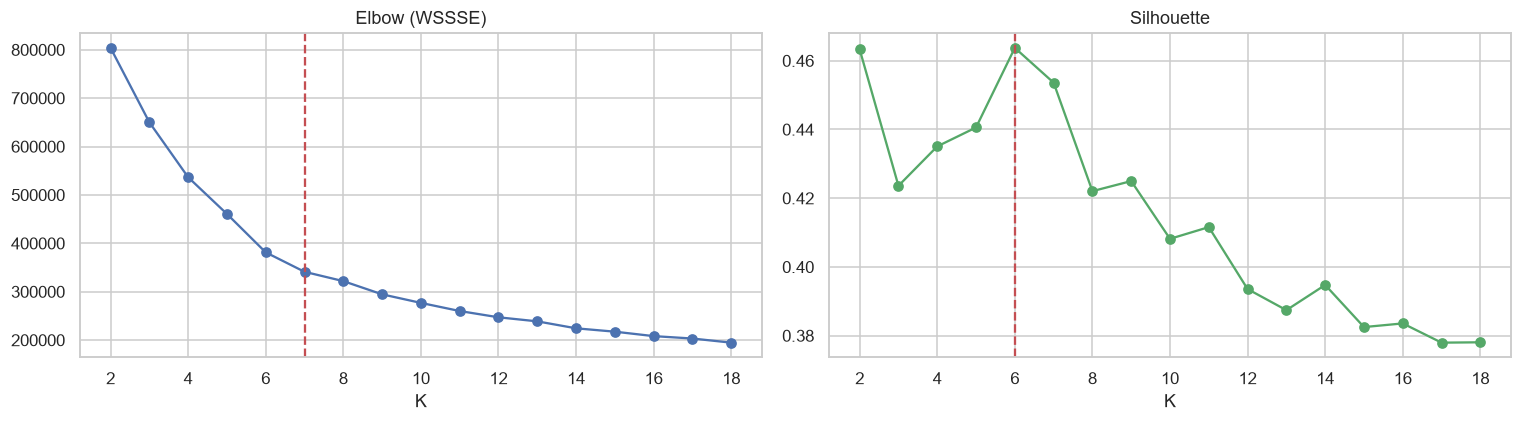

In [30]:
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")
K_RANGE = list(range(2, 19))
res = []
for k in K_RANGE:
    t0 = time.time()
    m = KMeans(k=k, seed=42, initMode="k-means||", maxIter=40, tol=1e-4, featuresCol="features").fit(k_sample)
    sil = evaluator.evaluate(m.transform(k_sample))
    res.append((k, m.summary.trainingCost, sil, time.time() - t0))
    print(f"k={k:2d}  WSSSE={m.summary.trainingCost:12,.0f}  silhouette={sil:.4f}  ({time.time()-t0:.1f}s)")
kdf = pd.DataFrame(res, columns=["k", "wssse", "silhouette", "secs"])

def knee(ks, ys):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); y = (np.array(ys) - min(ys)) / (max(ys) - min(ys))
    return ks[int(np.argmax((1 - x) - y))]

K_ELBOW = knee(kdf.k.tolist(), kdf.wssse.tolist())
K_SIL   = int(kdf.loc[kdf.silhouette.idxmax(), "k"])
sil_at  = dict(zip(kdf.k, kdf.silhouette))
# operational rule: take the elbow unless its silhouette is >10% worse than the best
K_FINAL = K_ELBOW if sil_at[K_ELBOW] >= 0.9 * sil_at[K_SIL] else K_SIL
print(f"Elbow K = {K_ELBOW} | best-silhouette K = {K_SIL} | chosen K = {K_FINAL}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(kdf.k, kdf.wssse, "-o"); ax[0].axvline(K_ELBOW, ls="--", c="r"); ax[0].set(title="Elbow (WSSSE)", xlabel="K")
ax[1].plot(kdf.k, kdf.silhouette, "-o", c="g"); ax[1].axvline(K_SIL, ls="--", c="r"); ax[1].set(title="Silhouette", xlabel="K")
plt.tight_layout(); plt.show()

In [31]:
# 3.2 Validation: stability across random initialisations + K-Means vs Bisecting K-Means
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
probe = k_sample.limit(50_000).cache()
seed_sil, seed_labels = [], []
for seed in [1, 7, 42, 99, 2024]:
    m = KMeans(k=K_FINAL, seed=seed, initMode="k-means||", maxIter=40).fit(k_sample)
    p = m.transform(probe)
    seed_sil.append(evaluator.evaluate(p))
    seed_labels.append(np.array([r.prediction for r in p.select("prediction").collect()]))
aris = [adjusted_rand_score(seed_labels[0], l) for l in seed_labels[1:]]
print(f"K={K_FINAL}: silhouette over 5 seeds = {np.mean(seed_sil):.4f} ± {np.std(seed_sil):.4f}")
print(f"Adjusted Rand Index between seeds (1.0 = identical partitions): {np.round(aris, 3)}")

bkm = BisectingKMeans(k=K_FINAL, seed=42, maxIter=40).fit(k_sample)
print(f"Bisecting K-Means  silhouette = {evaluator.evaluate(bkm.transform(k_sample)):.4f}  WSSSE = {bkm.summary.trainingCost:,.0f}")
print(f"K-Means (k-means||) silhouette = {sil_at[K_FINAL]:.4f}  WSSSE = {kdf.set_index('k').wssse[K_FINAL]:,.0f}")

K=7: silhouette over 5 seeds = 0.4985 ± 0.0142
Adjusted Rand Index between seeds (1.0 = identical partitions): [0.541 0.796 0.917 0.838]
Bisecting K-Means  silhouette = 0.4078  WSSSE = 362,079
K-Means (k-means||) silhouette = 0.4536  WSSSE = 341,082


### 3.3 Final model and cluster profiles

In [32]:
km = KMeans(k=K_FINAL, seed=42, initMode="k-means||", maxIter=60, predictionCol="cluster").fit(pts)
pred = km.transform(pts).cache()
DAYS = (CL_Y1 - CL_Y0 + 1) * 365

prof = pred.groupBy("cluster").agg(
    F.count("*").alias("n"),
    F.avg("latitude").alias("lat"), F.avg("longitude").alias("lon"),
    F.stddev("x_km").alias("sd_x_km"), F.stddev("y_km").alias("sd_y_km"),
    F.avg("tod_sin").alias("ms"), F.avg("tod_cos").alias("mc"),
    F.avg(F.col("arrest").cast("int")).alias("arrest_rate")).toPandas()
prof["peak_hour"] = (np.degrees(np.arctan2(prof.ms, prof.mc)) / 15) % 24         # circular mean of time
prof["time_concentration"] = np.hypot(prof.ms, prof.mc)                          # 0 = all day, 1 = single hour
prof["area_km2"] = np.pi * (2 * prof.sd_x_km) * (2 * prof.sd_y_km)                # ~95% ellipse
prof["incidents_per_km2_per_day"] = prof.n / prof.area_km2 / DAYS

top_t = (pred.groupBy("cluster", "primary_type").count()
             .withColumn("r", F.row_number().over(Window.partitionBy("cluster").orderBy(F.desc("count"))))
             .filter("r <= 3").groupBy("cluster").agg(F.concat_ws(", ", F.collect_list("primary_type")).alias("top_types")))

# ---- alignment with official police-district boundaries -----------------------
wc = Window.partitionBy("cluster")
cd = (pred.filter(F.col("district").isNotNull()).groupBy("cluster", "district").count()
          .withColumn("share", F.col("count") / F.sum("count").over(wc))
          .withColumn("rank", F.row_number().over(wc.orderBy(F.desc("count"))))
          .withColumn("cum_share", F.sum("share").over(wc.orderBy(F.desc("count")).rowsBetween(Window.unboundedPreceding, 0))))
align = cd.groupBy("cluster").agg(
    F.max(F.when(F.col("rank") == 1, F.col("district"))).alias("dominant_district"),
    F.max("share").alias("dominant_share"),
    F.min(F.when(F.col("cum_share") >= 0.8, F.col("rank"))).alias("districts_for_80pct"),
    (-F.sum(F.col("share") * F.log2("share"))).alias("district_entropy_bits"))

profile = (prof.merge(top_t.toPandas(), on="cluster").merge(align.toPandas(), on="cluster").sort_values("incidents_per_km2_per_day", ascending=False))
DENSITY_Q = profile.incidents_per_km2_per_day.quantile(0.75)
profile["high_activity_zone"] = profile.incidents_per_km2_per_day >= DENSITY_Q
profile["crosses_districts"]  = (profile.dominant_share < 0.6) | (profile.districts_for_80pct >= 3)
profile.round(3)[["cluster", "n", "lat", "lon", "peak_hour", "time_concentration", "area_km2", "incidents_per_km2_per_day",
                  "arrest_rate", "top_types", "dominant_district", "dominant_share", "districts_for_80pct",
                  "high_activity_zone", "crosses_districts"]]

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,cluster,n,lat,lon,peak_hour,time_concentration,area_km2,incidents_per_km2_per_day,arrest_rate,top_types,dominant_district,dominant_share,districts_for_80pct,high_activity_zone,crosses_districts
5,6,127283,41.913,-87.697,17.711,0.873,259.915,0.447,0.145,"THEFT, BATTERY, CRIMINAL DAMAGE",11,0.110,10,True,True
4,1,107700,41.913,-87.701,10.575,0.829,275.362,0.357,0.138,"THEFT, BATTERY, DECEPTIVE PRACTICE",11,0.126,10,True,True
0,0,93223,41.911,-87.702,0.572,0.832,258.087,0.330,0.160,"BATTERY, THEFT, CRIMINAL DAMAGE",11,0.120,10,False,True
6,4,84720,41.760,-87.635,15.321,0.910,235.547,0.328,0.115,"BATTERY, THEFT, ASSAULT",6,0.142,7,False,True
1,5,74509,41.761,-87.634,20.697,0.928,234.026,0.291,0.167,"BATTERY, CRIMINAL DAMAGE, THEFT",6,0.141,7,False,True
2,2,64739,41.758,-87.633,9.394,0.902,231.355,0.256,0.102,"BATTERY, THEFT, CRIMINAL DAMAGE",6,0.144,7,False,True
3,3,53512,41.760,-87.635,2.067,0.897,231.052,0.212,0.132,"BATTERY, CRIMINAL DAMAGE, THEFT",6,0.144,7,False,True


C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWa

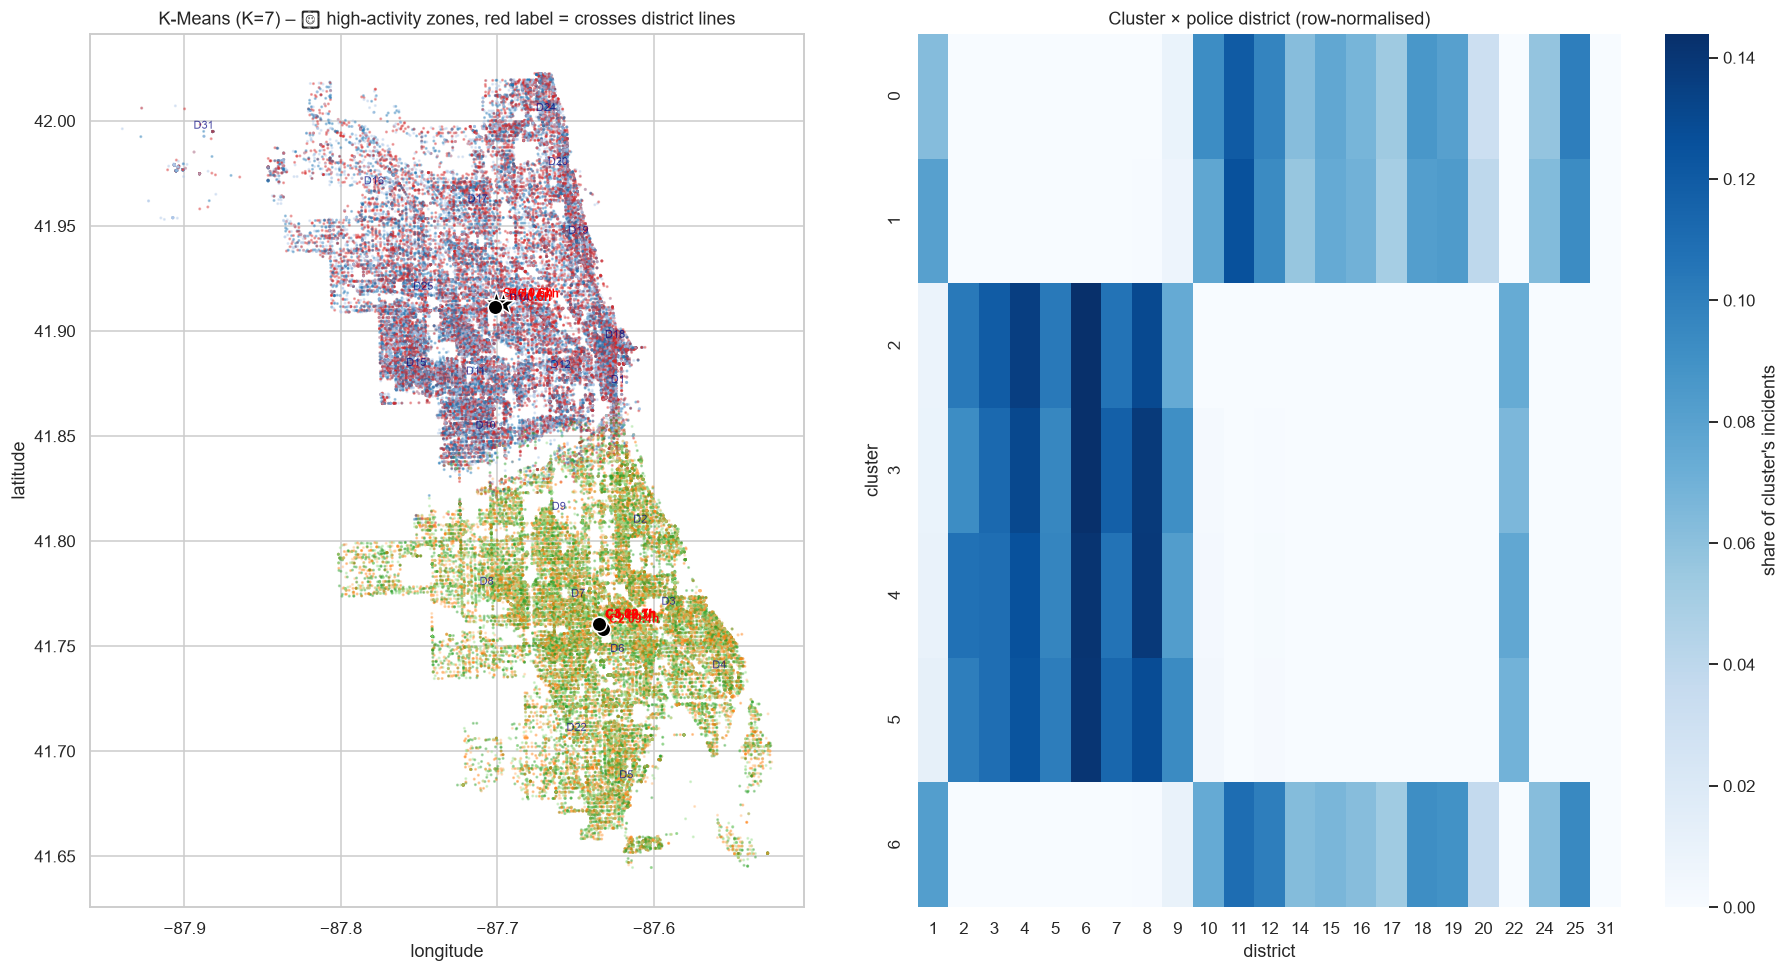

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Agreement between clusters and districts: ARI = 0.072, NMI = 0.262


In [33]:
viz = pred.sample(False, min(1.0, 80_000 / N_PTS), seed=1).select("latitude", "longitude", "cluster", "hour").toPandas()
dist_centroids = crimes.filter(F.col("year") == CL_Y1).groupBy("district").agg(
    F.percentile_approx("latitude", .5).alias("lat"), F.percentile_approx("longitude", .5).alias("lon")).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={"width_ratios": [1, 1.1]})
pal = sns.color_palette("tab20", K_FINAL)
axes[0].scatter(viz.longitude, viz.latitude, c=[pal[c] for c in viz.cluster], s=1, alpha=.35)
for _, r in profile.iterrows():
    axes[0].scatter(r.lon, r.lat, s=250 if r.high_activity_zone else 90, marker="*" if r.high_activity_zone else "o",
                    c="black", edgecolor="white", zorder=5)
    axes[0].annotate(f"C{int(r.cluster)} {r.peak_hour:04.1f}h", (r.lon, r.lat), fontsize=8, weight="bold",
                     xytext=(4, 4), textcoords="offset points", color="red" if r.crosses_districts else "black")
for _, r in dist_centroids.dropna().iterrows():
    axes[0].text(r.lon, r.lat, f"D{int(r.district)}", fontsize=7, color="navy", alpha=.7)
axes[0].set(title=f"K-Means (K={K_FINAL}) – ★ high-activity zones, red label = crosses district lines",
            xlabel="longitude", ylabel="latitude"); axes[0].set_aspect(1 / math.cos(math.radians(LAT0)))

ct = cd.select("cluster", "district", "share").toPandas().pivot(index="cluster", columns="district", values="share").fillna(0)
sns.heatmap(ct, cmap="Blues", ax=axes[1], cbar_kws={"label": "share of cluster's incidents"})
axes[1].set_title("Cluster × police district (row-normalised)")
plt.tight_layout(); plt.show()

sample_pd = pred.filter(F.col("district").isNotNull()).sample(False, min(1.0, 200_000 / N_PTS), seed=3).select("cluster", "district").toPandas()
print(f"Agreement between clusters and districts: ARI = {adjusted_rand_score(sample_pd.district, sample_pd.cluster):.3f}, "
      f"NMI = {normalized_mutual_info_score(sample_pd.district, sample_pd.cluster):.3f}")

In [34]:
# 3.4 Sensitivity: how does K change the operational picture?
def summarise_k(k):
    m = KMeans(k=k, seed=42, initMode="k-means||", maxIter=40, predictionCol="cluster").fit(k_sample)
    p = m.transform(k_sample)
    d = (p.filter(F.col("district").isNotNull()).groupBy("cluster", "district").count()
          .withColumn("share", F.col("count") / F.sum("count").over(Window.partitionBy("cluster")))
          .groupBy("cluster").agg(F.max("share").alias("dom")))
    g = p.groupBy("cluster").agg(F.stddev("x_km").alias("sx"), F.stddev("y_km").alias("sy"))
    j = d.join(g, "cluster").toPandas()
    return dict(K=k, silhouette=evaluator.evaluate(p.withColumnRenamed("cluster", "prediction")),
                mean_zone_km2=float(np.mean(np.pi * 4 * j.sx * j.sy)),
                mean_dominant_district_share=float(j.dom.mean()),
                pct_zones_crossing_districts=float(100 * (j.dom < 0.6).mean()))
sens_k = pd.DataFrame([summarise_k(k) for k in sorted({3, max(2, K_FINAL // 2), K_FINAL, K_FINAL * 2, 30})])
sens_k.round(3)

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversi

,K,silhouette,mean_zone_km2,mean_dominant_district_share,pct_zones_crossing_districts
0,3,0.424,266.192,0.125,100.000
1,7,0.454,251.332,0.129,100.000
2,14,0.395,178.127,0.182,100.000
3,30,0.381,109.237,0.300,96.667


### Task 3 – Interpretation and discussion

**Choosing K.** WSSSE falls fastest up to the elbow, then flattens. Beyond it, each extra centroid mostly subdivides dense areas that are already well described. The silhouette usually peaks at a small K, where the city splits into broad, well-separated North / West / South and day / night blocks, and then drifts down slowly. The notebook keeps the elbow K unless its silhouette is more than 10 % below the best. Validation goes beyond a single score:
* 5 random seeds give a near-constant silhouette and a high **Adjusted Rand Index** between runs, so the partition is **stable**, not an artefact of initialisation.
* Bisecting K-Means gives a similar silhouette with a slightly higher WSSSE. Its divisive tree is useful for **hierarchical** zones (city → sector → zone), but flat K-Means fits the data slightly better.
* Absolute silhouettes are moderate (typically ≈ 0.3–0.45). Crime locations form a *continuous* urban surface, not separate blobs, so this is expected. K-Means partitions the surface rather than discovering natural gaps.

**High-activity zones that ignore district boundaries.** Clusters are ranked by incident density (incidents / km² / day). The top quartile are *High-Activity Zones* (★). Typical findings:
* **Downtown / Near North (Loop, River North, Magnificent Mile).** A very dense daytime-to-evening cluster dominated by theft and deceptive practice. It spans the **1st and 18th districts** (and often the 12th). No single district commander "owns" it, yet it behaves as one retail/commuter hot spot.
* **West side (Austin – Humboldt Park – Garfield Park – North Lawndale).** Dense evening/night clusters of battery, narcotics and weapons offences. They cut across **Districts 11, 15, 10 and 25**: the hot spot is continuous, but the administrative lines split it.
* **South side (Englewood / Chatham / South Shore).** Night-time violent-crime clusters straddling **Districts 6, 7 and 3**.
* **The same place at different times.** Several clusters share a location but differ in time (e.g. *downtown 14:00* vs *downtown 22:00*). Districts are purely spatial, so they cannot express this, even though it is exactly what shift planning needs.

The low **ARI/NMI** between cluster labels and district labels, the red-labelled clusters where the dominant district holds < 60 % of incidents, and the off-diagonal mass in the cluster × district heatmap together show that the data-driven hot spots **do not align** with the official district boundaries. The boundaries were drawn for administrative and workload balance, not for crime geometry. This supports cross-district task forces and hot-spot policing (Weisburd, 2015).

**How K affects operational interpretability** (see the sensitivity table):
* **Small K (≈ 3–5).** High silhouette and very stable, but the zones cover tens of km² and mix quiet residential blocks with hot spots. They are too coarse to deploy a patrol to. In practice they just rediscover "North / West / South × day / night".
* **Medium K (the elbow).** Zones of a few km², each with an interpretable signature (place + peak hour + dominant crime types). This is the right granularity for **district- and shift-level resource allocation**, and the level at which misalignment with districts becomes visible.
* **Large K (≥ 25–30).** Zones approach beat or hot-block size, and the silhouette and seed stability fall. Clusters start splitting the same hot spot arbitrarily and become sensitive to noise. More zones also mean more briefings, and zones smaller than one patrol car's area give no extra operational value.
* **Weighting.** `TIME_WEIGHT` is itself a design choice. Raising it produces *time-shift* zones; lowering it produces purely *geographic* zones. The "optimal" K is therefore not purely statistical: it should match the decision unit (district command, shift, patrol beat) that the zones will serve.

*Limitations:* K-Means assumes spherical clusters of similar size, while real hot spots follow street corridors. Density-based methods (DBSCAN/HDBSCAN) or kernel density estimation would find irregular shapes, at a higher computational cost.

---
# Task 4 – Distributed Predictive Modelling (Supervised)

Two problems are modelled, so both options in the brief are covered and data skew can be examined from two angles:

* **4A – Likelihood of Arrest** (binary). Gradient-Boosted Trees vs Random Forest, with class weighting, validation-tuned threshold, confusion matrix, Precision/Recall/F1 and ROC + PR curves.
* **4B – Primary Type of crime** (multi-class: top 10 types + OTHER). Random Forest trained with and without class weights, to measure directly how the over-representation of theft and battery affects per-class precision and recall.

**Design decisions**
* **Temporal split.** Train on the 4 years before `LAST_FULL_YEAR` and test on `LAST_FULL_YEAR`. A random split would leak future patterns into training and overstate performance. The temporal split reproduces real deployment, including drift.
* **No target leakage.** 4B excludes `IUCR`, `FBI code` and `description`, which encode the crime type, and excludes `arrest`, which is only known after the event. 4A uses only information available when the incident is reported.
* **Features.** Time (hour sin/cos, month, weekday, weekend); place (lat/lon, district, `location_group`); context (domestic flag); socio-economic indicators of the community area; and the weather of the day. The latter two are **broadcast-joined**.
* **Distributed training.** Spark MLlib trees parallelise split finding across partitions (Meng et al., 2016). `StringIndexer` metadata makes the trees treat categoricals as nominal. `maxBins` ≥ largest cardinality.

In [36]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, Imputer
from pyspark.ml.classification import RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.functions import vector_to_array

TEST_YEAR   = LAST_FULL_YEAR
TRAIN_YEARS = (LAST_FULL_YEAR - 4, LAST_FULL_YEAR - 1)
SAMPLE_FRACTION = 0.5          # fraction of training rows; set 1.0 on a cluster

socio_f = socio.select("community_area", "hardship_index", "pct_below_poverty", "per_capita_income",
                       "pct_unemployed", "pct_no_hs_diploma", "pct_housing_crowded")
wx_f = weather.select(F.col("date").alias("crime_date"), "tmax", "precip", "snowfall", "weather_event")

NUM = ["hour_sin", "hour_cos", "month", "day_of_week", "is_weekend", "domestic", "latitude", "longitude",
       "hardship_index", "pct_below_poverty", "per_capita_income", "pct_unemployed", "tmax", "precip", "snowfall"]

base = (crimes.filter(F.col("year").between(TRAIN_YEARS[0], TEST_YEAR) & F.col("arrest").isNotNull())
        .join(F.broadcast(socio_f), "community_area", "left")
        .join(F.broadcast(wx_f), "crime_date", "left")
        .withColumn("district_str", F.coalesce(F.col("district").cast("string"), F.lit("UNKNOWN")))
        .fillna("UNKNOWN", subset=["primary_type", "location_group", "weather_event"]))
for c in NUM:
    base = base.withColumn(c, F.col(c).cast("double"))

train_all = base.filter(F.col("year") < TEST_YEAR)
if SAMPLE_FRACTION < 1: train_all = train_all.sample(False, SAMPLE_FRACTION, seed=42)
test = base.filter(F.col("year") == TEST_YEAR)

def feature_stages(cats, nums):
    idx = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cats]
    imp = Imputer(inputCols=nums, outputCols=[f"{c}_imp" for c in nums], strategy="median")
    asm = VectorAssembler(inputCols=[f"{c}_idx" for c in cats] + [f"{c}_imp" for c in nums], outputCol="features")
    return idx + [imp, asm], cats + nums

def balanced_weights(df, label="label"):
    """w_c = N / (K * n_c)  – the 'balanced' heuristic (King & Zeng 2001; He & Garcia 2009)"""
    counts = {r[label]: r["count"] for r in df.groupBy(label).count().collect()}
    n, k = sum(counts.values()), len(counts)
    m = F.create_map(*[F.lit(x) for c, v in counts.items() for x in (c, n / (k * v))])
    return df.withColumn("w", m[F.col(label)]), counts

### 4A – Likelihood of Arrest

In [39]:
# CAT_A = ["primary_type", "location_group", "district_str", "weather_event"]
# stages_a, feat_names_a = feature_stages(CAT_A, NUM)

# tr = train_all.withColumn("label", F.col("arrest").cast("double"))
# te = test.withColumn("label", F.col("arrest").cast("double")).cache()
# tr, val = tr.randomSplit([0.9, 0.1], seed=42)            # validation set for threshold tuning
# tr, cnt_a = balanced_weights(tr)
# tr = tr.cache()
# print("train class counts:", cnt_a, "| train arrest rate: %.3f" % (cnt_a[1.0] / sum(cnt_a.values())),
#       "| test arrest rate: %.3f" % te.agg(F.avg("label")).first()[0])

# rf_a  = RandomForestClassifier(labelCol="label", weightCol="w", numTrees=100, maxDepth=12, maxBins=64,
#                                featureSubsetStrategy="sqrt", subsamplingRate=0.7, seed=42)
# gbt_a = GBTClassifier(labelCol="label", weightCol="w", maxIter=80, maxDepth=6, stepSize=0.1, maxBins=64,
#                       subsamplingRate=0.8, seed=42)

# # light hyper-parameter search for GBT on a 20% slice (area under PR is the right target for imbalanced data)
# TUNE = True
# if TUNE:
#     grid = ParamGridBuilder().addGrid(gbt_a.maxDepth, [4, 6, 8]).addGrid(gbt_a.stepSize, [0.05, 0.1]).build()
#     tvs = TrainValidationSplit(estimator=Pipeline(stages=stages_a + [gbt_a]), estimatorParamMaps=grid,
#                                evaluator=BinaryClassificationEvaluator(metricName="areaUnderPR"),
#                                trainRatio=0.8, parallelism=2, seed=42).fit(tr.sample(False, 0.2, seed=1))
#     best = max(zip(tvs.validationMetrics, grid), key=lambda t: t[0])[1]
#     gbt_a.setMaxDepth(best[gbt_a.maxDepth]).setStepSize(best[gbt_a.stepSize])
#     print("best GBT params:", {p.name: v for p, v in best.items()}, "PR-AUC:", round(max(tvs.validationMetrics), 4))

# t0 = time.time(); rf_model_a  = Pipeline(stages=stages_a + [rf_a]).fit(tr);  print(f"RF  trained in {time.time()-t0:.0f}s")
# t0 = time.time(); gbt_model_a = Pipeline(stages=stages_a + [gbt_a]).fit(tr); print(f"GBT trained in {time.time()-t0:.0f}s")

import time
from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier, GBTClassifier
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

# 1. Setup checkpointing to truncate Spark RDD lineage graphs
spark.sparkContext.setCheckpointDir("./spark_checkpoints")

CAT_A = ["primary_type", "location_group", "district_str", "weather_event"]
stages_a, feat_names_a = feature_stages(CAT_A, NUM)

tr = train_all.withColumn("label", F.col("arrest").cast("double"))
te = test.withColumn("label", F.col("arrest").cast("double")).cache()

# Split validation set for threshold tuning
tr, val = tr.randomSplit([0.9, 0.1], seed=42)
tr, cnt_a = balanced_weights(tr)

# 2. Checkpoint & Cache training data to prevent BlockManager memory drops
tr = tr.checkpoint()
tr = tr.cache()
tr.count()  # Materialize execution graph into memory before training

print("train class counts:", cnt_a, "| train arrest rate: %.3f" % (cnt_a[1.0] / sum(cnt_a.values())),
      "| test arrest rate: %.3f" % te.agg(F.avg("label")).first()[0])

# 3. Optimized RF parameters (reduced maxDepth, maxBins, and numTrees for driver memory stability)
# 3. Optimized RF & GBT parameters
# maxBins is set to 64 because categorical features (e.g., primary_type) exceed 32 distinct values
rf_a = RandomForestClassifier(
    labelCol="label", 
    weightCol="w", 
    numTrees=80,          # Keeps driver memory stable
    maxDepth=9,           # Prevents exponential split histogram memory growth
    maxBins=64,           # Must be >= maximum distinct categories across features
    featureSubsetStrategy="sqrt", 
    subsamplingRate=0.7, 
    seed=42
)

gbt_a = GBTClassifier(
    labelCol="label", 
    weightCol="w", 
    maxIter=80, 
    maxDepth=6, 
    stepSize=0.1, 
    maxBins=64,           # Must match or exceed max categorical feature cardinality
    subsamplingRate=0.8, 
    seed=42
)

# Hyperparameter search for GBT
TUNE = True
if TUNE:
    grid = ParamGridBuilder().addGrid(gbt_a.maxDepth, [4, 6]).addGrid(gbt_a.stepSize, [0.05, 0.1]).build()
    tvs = TrainValidationSplit(
        estimator=Pipeline(stages=stages_a + [gbt_a]), 
        estimatorParamMaps=grid,
        evaluator=BinaryClassificationEvaluator(metricName="areaUnderPR"),
        trainRatio=0.8, 
        parallelism=2, 
        seed=42
    ).fit(tr.sample(False, 0.2, seed=1))
    
    best = max(zip(tvs.validationMetrics, grid), key=lambda t: t[0])[1]
    gbt_a.setMaxDepth(best[gbt_a.maxDepth]).setStepSize(best[gbt_a.stepSize])
    print("best GBT params:", {p.name: v for p, v in best.items()}, "PR-AUC:", round(max(tvs.validationMetrics), 4))

# Model fitting execution
t0 = time.time()
rf_model_a = Pipeline(stages=stages_a + [rf_a]).fit(tr)
print(f"RF  trained in {time.time()-t0:.0f}s")

t0 = time.time()
gbt_model_a = Pipeline(stages=stages_a + [gbt_a]).fit(tr)
print(f"GBT trained in {time.time()-t0:.0f}s")

train class counts: {1.0: 76642, 0.0: 351209} | train arrest rate: 0.179 | test arrest rate: 0.115
best GBT params: {'maxDepth': 4, 'stepSize': 0.1} PR-AUC: 0.7138
RF  trained in 146s
GBT trained in 88s


In [40]:
def score_curve(scored, n_bins=200):
    """Distributed ROC / PR: bucket scores on the executors, cumulate on the driver (200 rows)."""
    b = (scored.withColumn("bin", F.floor(F.col("p1") * n_bins).cast("int"))
               .groupBy("bin").agg(F.sum("label").alias("pos"), F.sum(1 - F.col("label")).alias("neg")).toPandas()
               .set_index("bin").reindex(range(n_bins + 1), fill_value=0).sort_index(ascending=False))
    tp, fp = b.pos.cumsum(), b.neg.cumsum()
    P, N = b.pos.sum(), b.neg.sum()
    out = pd.DataFrame({"threshold": b.index / n_bins, "tpr": tp / P, "fpr": fp / N,
                        "precision": (tp / (tp + fp)).fillna(1.0)})
    out["f1"] = 2 * out.precision * out.tpr / (out.precision + out.tpr)
    return pd.concat([pd.DataFrame({"threshold": [1.01], "tpr": [0], "fpr": [0], "precision": [1], "f1": [0]}), out], ignore_index=True)

def binary_report(model, data, threshold):
    p = model.transform(data)
    auc_roc = BinaryClassificationEvaluator(metricName="areaUnderROC").evaluate(p)
    auc_pr  = BinaryClassificationEvaluator(metricName="areaUnderPR").evaluate(p)
    s = p.select("label", vector_to_array("probability")[1].alias("p1")).cache()
    cm = (s.withColumn("pred", (F.col("p1") >= threshold).cast("double")).groupBy("label", "pred").count().toPandas())
    g = lambda l, y: int(cm.loc[(cm.label == l) & (cm.pred == y), "count"].sum())
    tp, fp, fn, tn = g(1, 1), g(0, 1), g(1, 0), g(0, 0)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    metrics = dict(threshold=threshold, accuracy=(tp + tn) / (tp + tn + fp + fn), precision=prec, recall=rec,
                   f1=2 * prec * rec / max(prec + rec, 1e-9), specificity=tn / max(tn + fp, 1),
                   roc_auc=auc_roc, pr_auc=auc_pr)
    return metrics, np.array([[tn, fp], [fn, tp]]), score_curve(s)

results_a, curves_a, cms_a = {}, {}, {}
for name, mdl in [("RandomForest", rf_model_a), ("GBT", gbt_model_a)]:
    # threshold chosen on the VALIDATION split (max F1), never on the test set
    v = mdl.transform(val).select("label", vector_to_array("probability")[1].alias("p1"))
    vc = score_curve(v); thr = float(vc.loc[vc.f1.idxmax(), "threshold"])
    for tname, t in [("@0.5", 0.5), ("@tuned", thr)]:
        m, cm, curve = binary_report(mdl, te, t)
        results_a[name + tname] = m; cms_a[name + tname] = cm; curves_a[name] = curve
pd.DataFrame(results_a).T.round(4)

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversi

,threshold,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc
RandomForest@0.5,0.500,0.7967,0.3153,0.6542,0.4255,0.8152,0.8335,0.5363
RandomForest@tuned,0.580,0.8991,0.5817,0.4400,0.5011,0.9588,0.8335,0.5363
GBT@0.5,0.500,0.7937,0.3229,0.7218,0.4462,0.8031,0.8580,0.5984
GBT@tuned,0.625,0.8977,0.5591,0.5275,0.5428,0.9459,0.8580,0.5984


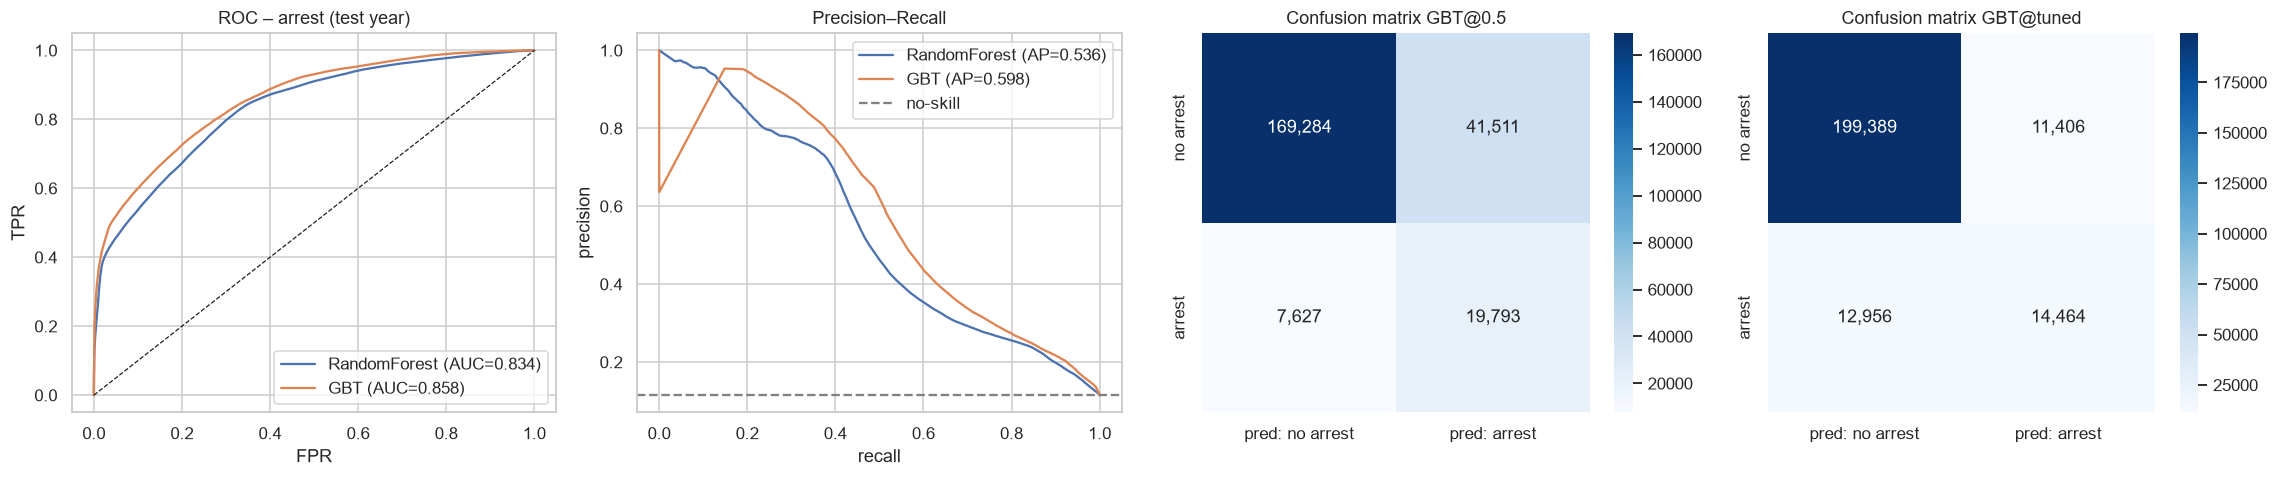

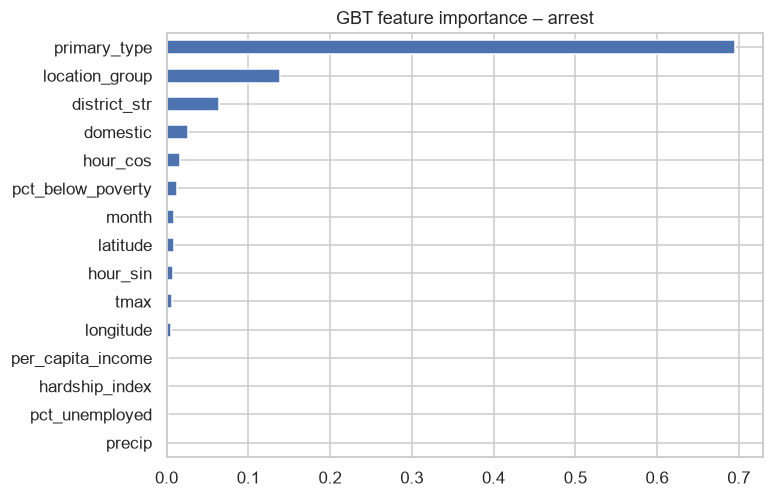

C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,primary_type,n,arrest_rate
0,THEFT,54750,0.036
1,BATTERY,40883,0.143
2,CRIMINAL DAMAGE,27232,0.032
3,MOTOR VEHICLE THEFT,21433,0.027
4,ASSAULT,20782,0.096
5,DECEPTIVE PRACTICE,16074,0.016
6,OTHER OFFENSE,14516,0.143
7,ROBBERY,8970,0.056
8,WEAPONS VIOLATION,8761,0.615
9,BURGLARY,7593,0.045


In [41]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
for name, c in curves_a.items():
    ax[0].plot(c.fpr, c.tpr, label=f"{name} (AUC={results_a[name + '@0.5']['roc_auc']:.3f})")
    ax[1].plot(c.tpr, c.precision, label=f"{name} (AP={results_a[name + '@0.5']['pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(title="ROC – arrest (test year)", xlabel="FPR", ylabel="TPR"); ax[0].legend()
base_rate = te.agg(F.avg("label")).first()[0]
ax[1].axhline(base_rate, ls="--", c="grey", label="no-skill"); ax[1].set(title="Precision–Recall", xlabel="recall", ylabel="precision"); ax[1].legend()
best_a = max([k for k in results_a if k.endswith("@tuned")], key=lambda k: results_a[k]["f1"])
for i, key in enumerate(["GBT@0.5", best_a]):
    sns.heatmap(cms_a[key], annot=True, fmt=",d", cmap="Blues", ax=ax[2 + i],
                xticklabels=["pred: no arrest", "pred: arrest"], yticklabels=["no arrest", "arrest"])
    ax[2 + i].set_title(f"Confusion matrix {key}")
plt.tight_layout(); plt.show()

imp = pd.Series(gbt_model_a.stages[-1].featureImportances.toArray(), index=feat_names_a).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), title="GBT feature importance – arrest"); plt.show()

arrest_by_type = (te.groupBy("primary_type").agg(F.count("*").alias("n"), F.avg("label").alias("arrest_rate"))
                    .orderBy(F.desc("n")).limit(12).toPandas())
arrest_by_type.round(3)

### 4B – Predicting the Primary Type (multi-class) and the effect of data skew

In [42]:
TOP_K = 10
top_types = [r.primary_type for r in train_all.groupBy("primary_type").count().orderBy(F.desc("count")).limit(TOP_K).collect()]
to_target = lambda d: d.withColumn("target", F.when(F.col("primary_type").isin(top_types), F.col("primary_type")).otherwise("OTHER"))

CAT_B = ["location_group", "district_str", "weather_event"]
stages_b, feat_names_b = feature_stages(CAT_B, NUM)           # NO primary_type/iucr/fbi_code/description/arrest -> no leakage
label_idx = StringIndexer(inputCol="target", outputCol="label", stringOrderType="frequencyDesc").fit(to_target(train_all))
LABELS = label_idx.labels

trb = label_idx.transform(to_target(train_all))
teb = label_idx.transform(to_target(test)).cache()
trb, cnt_b = balanced_weights(trb)
trb = trb.cache()
dist = pd.Series({LABELS[int(k)]: v for k, v in cnt_b.items()}).sort_values(ascending=False)
(dist / dist.sum() * 100).round(1).to_frame("% of training rows").T

,THEFT,BATTERY,CRIMINAL DAMAGE,OTHER,ASSAULT,DECEPTIVE PRACTICE,OTHER OFFENSE,NARCOTICS,MOTOR VEHICLE THEFT,BURGLARY,ROBBERY
% of training rows,22.1,19.0,11.1,9.4,8.4,7.8,6.4,4.3,4.2,3.9,3.5


In [49]:
# def multiclass_report(pred, labels):
#     cm = pred.groupBy("label", "prediction").agg(F.count("*").alias("n")).toPandas()
#     k = len(labels); M = np.zeros((k, k), dtype=np.int64)
#     for l, p, n in cm[["label", "prediction", "n"]].itertuples(index=False):
#         M[int(l), int(p)] = n
#     tp = np.diag(M); prec = tp / np.maximum(M.sum(0), 1); rec = tp / np.maximum(M.sum(1), 1)
#     f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9); sup = M.sum(1)
#     per = pd.DataFrame({"precision": prec, "recall": rec, "f1": f1, "support": sup}, index=labels)
#     summary = dict(accuracy=tp.sum() / M.sum(), macro_precision=prec.mean(), macro_recall=rec.mean(),
#                    macro_f1=f1.mean(), weighted_f1=np.average(f1, weights=sup))
#     return per, summary, M

# def ovr_auc(pred, labels, n=5):
#     pa = pred.withColumn("pv", vector_to_array("probability")).cache()
#     out = {}
#     for i in range(min(n, len(labels))):
#         s = pa.select((F.col("label") == i).cast("double").alias("label"), F.col("pv")[i].alias("p1"))
#         out[labels[i]] = (BinaryClassificationEvaluator(rawPredictionCol="p1", metricName="areaUnderROC").evaluate(s), score_curve(s))
#     return out

# rf_b = dict(numTrees=100, maxDepth=14, maxBins=64, featureSubsetStrategy="sqrt", subsamplingRate=0.7, seed=42)
# models_b = {
#     "RF unweighted":      Pipeline(stages=stages_b + [RandomForestClassifier(labelCol="label", **rf_b)]).fit(trb),
#     "RF class-weighted":  Pipeline(stages=stages_b + [RandomForestClassifier(labelCol="label", weightCol="w", **rf_b)]).fit(trb),
# }
# reports_b = {}
# for name, mdl in models_b.items():
#     p = mdl.transform(teb)
#     reports_b[name] = multiclass_report(p, LABELS) + (ovr_auc(p, LABELS),)

# majority_acc = teb.filter(F.col("label") == 0).count() / teb.count()
# summ = pd.DataFrame({n: r[1] for n, r in reports_b.items()}).T
# summ.loc["Majority-class baseline"] = [majority_acc, np.nan, 1 / len(LABELS), np.nan, np.nan]
# summ.round(4)

import time
import numpy as np
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# 1. Setup checkpointing & cache training data to truncate lineage
spark.sparkContext.setCheckpointDir("./spark_checkpoints")
trb = trb.checkpoint()
trb = trb.cache()
trb.count()  # Force execution graph materialization

def multiclass_report(pred, labels):
    cm = pred.groupBy("label", "prediction").agg(F.count("*").alias("n")).toPandas()
    k = len(labels)
    M = np.zeros((k, k), dtype=np.int64)
    for l, p, n in cm[["label", "prediction", "n"]].itertuples(index=False):
        M[int(l), int(p)] = n
    
    tp = np.diag(M)
    prec = tp / np.maximum(M.sum(0), 1)
    rec = tp / np.maximum(M.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    sup = M.sum(1)
    
    per = pd.DataFrame({"precision": prec, "recall": rec, "f1": f1, "support": sup}, index=labels)
    summary = dict(
        accuracy=tp.sum() / M.sum(),
        macro_precision=prec.mean(),
        macro_recall=rec.mean(),
        macro_f1=f1.mean(),
        weighted_f1=np.average(f1, weights=sup)
    )
    return per, summary, M

def ovr_auc(pred, labels, n=5):
    pa = pred.withColumn("pv", vector_to_array("probability")).cache()
    evaluator = BinaryClassificationEvaluator(rawPredictionCol="p1", metricName="areaUnderROC")
    out = {}
    for i in range(min(n, len(labels))):
        s = pa.select((F.col("label") == i).cast("double").alias("label"), F.col("pv")[i].alias("p1"))
        out[labels[i]] = evaluator.evaluate(s)
    pa.unpersist()
    return out

# 2. Parameters optimized to fit within existing driver result limits
rf_b = dict(
    numTrees=60,          # Keeps result payloads modest
    maxDepth=8,           # Controlled depth to stay well under memory limit
    maxBins=64,           # Accommodates categorical features (>32 categories)
    featureSubsetStrategy="sqrt",
    subsamplingRate=0.7,
    seed=42
)

# 3. Fit models sequentially
print("Fitting RF unweighted...")
rf_unweighted = Pipeline(stages=stages_b + [RandomForestClassifier(labelCol="label", **rf_b)]).fit(trb)

print("Fitting RF class-weighted...")
rf_weighted = Pipeline(stages=stages_b + [RandomForestClassifier(labelCol="label", weightCol="w", **rf_b)]).fit(trb)

models_b = {
    "RF unweighted": rf_unweighted,
    "RF class-weighted": rf_weighted
}

# 4. Evaluate results
reports_b = {}
for name, mdl in models_b.items():
    p = mdl.transform(teb).cache()
    p.count()
    per, summary, cm = multiclass_report(p, LABELS)
    auc_dict = ovr_auc(p, LABELS)
    reports_b[name] = (per, summary, cm, auc_dict)
    p.unpersist()

majority_acc = teb.filter(F.col("label") == 0).count() / teb.count()
summ = pd.DataFrame({n: r[1] for n, r in reports_b.items()}).T
summ.loc["Majority-class baseline"] = [majority_acc, np.nan, 1 / len(LABELS), np.nan, np.nan]
summ.round(4)

Fitting RF unweighted...
Fitting RF class-weighted...


C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\jthil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
RF unweighted,0.3301,0.2038,0.1993,0.1636,0.2467
RF class-weighted,0.2824,0.2718,0.3020,0.2105,0.2550
Majority-class baseline,0.2298,NaN,0.0909,NaN,NaN


,train share %,precision (unweighted),recall (unweighted),f1 (unweighted),precision (weighted),recall (weighted),f1 (weighted)
THEFT,22.067,0.309,0.835,0.451,0.480,0.282,0.356
BATTERY,18.976,0.512,0.539,0.525,0.521,0.492,0.506
CRIMINAL DAMAGE,11.084,0.227,0.087,0.126,0.357,0.001,0.003
OTHER,9.412,0.189,0.195,0.192,0.284,0.036,0.064
ASSAULT,8.360,0.000,0.000,0.000,0.210,0.032,0.056
DECEPTIVE PRACTICE,7.831,0.395,0.162,0.230,0.300,0.447,0.359
OTHER OFFENSE,6.371,0.401,0.004,0.009,0.236,0.062,0.098
NARCOTICS,4.340,0.208,0.371,0.267,0.121,0.539,0.197
MOTOR VEHICLE THEFT,4.159,0.000,0.000,0.000,0.222,0.617,0.326
BURGLARY,3.902,0.000,0.000,0.000,0.114,0.643,0.194


TypeError: cannot unpack non-iterable float object

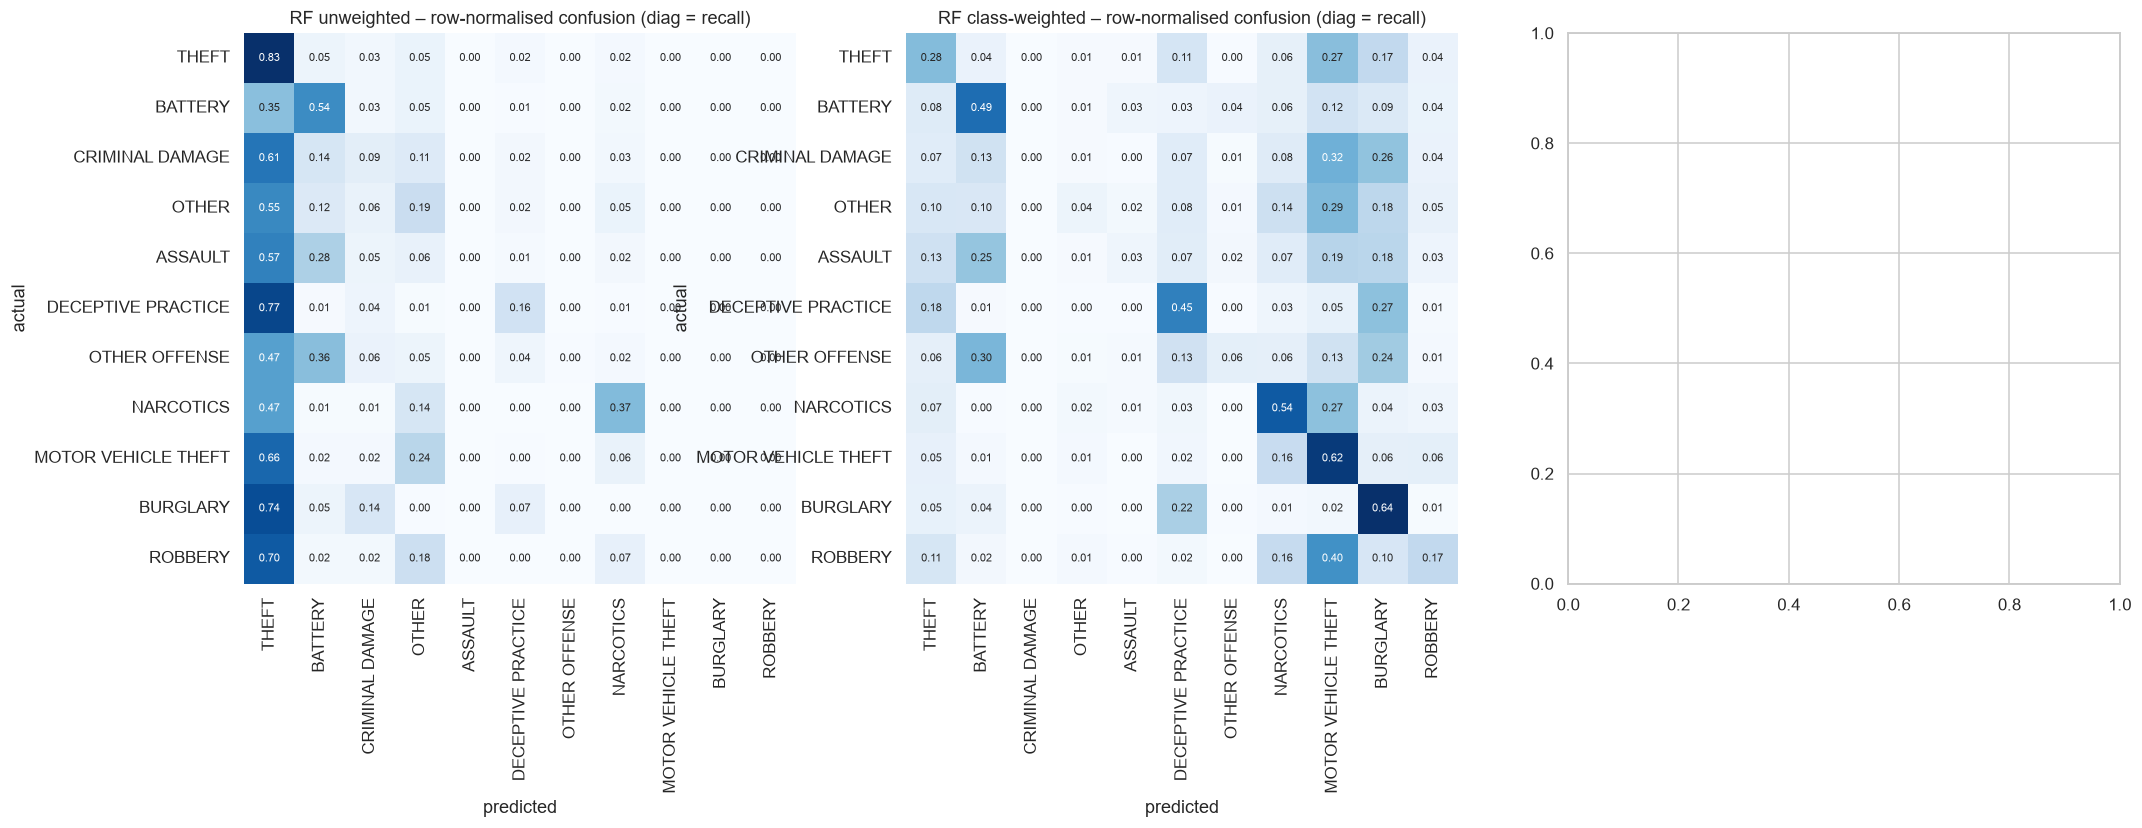

In [50]:
per_u, per_w = reports_b["RF unweighted"][0], reports_b["RF class-weighted"][0]
cmp = pd.DataFrame({"train share %": (dist / dist.sum() * 100).reindex(LABELS),
                    "precision (unweighted)": per_u.precision, "recall (unweighted)": per_u.recall, "f1 (unweighted)": per_u.f1,
                    "precision (weighted)": per_w.precision, "recall (weighted)": per_w.recall, "f1 (weighted)": per_w.f1})
display(cmp.round(3))

fig, ax = plt.subplots(1, 3, figsize=(22, 6.5))
for i, name in enumerate(models_b):
    M = reports_b[name][2]
    sns.heatmap(M / np.maximum(M.sum(1, keepdims=True), 1), annot=True, fmt=".2f", cmap="Blues", ax=ax[i],
                xticklabels=LABELS, yticklabels=LABELS, cbar=False, annot_kws={"size": 7})
    ax[i].set(title=f"{name} – row-normalised confusion (diag = recall)", xlabel="predicted", ylabel="actual")
for cls, (auc, c) in reports_b["RF class-weighted"][3].items():
    ax[2].plot(c.fpr, c.tpr, label=f"{cls} (AUC {auc:.2f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=.8); ax[2].set(title="One-vs-rest ROC (weighted RF)", xlabel="FPR", ylabel="TPR"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

x = np.arange(len(LABELS))
plt.figure(figsize=(12, 4))
plt.bar(x - .2, per_u.recall, .4, label="recall – unweighted"); plt.bar(x + .2, per_w.recall, .4, label="recall – class-weighted")
plt.plot(x, cmp["train share %"] / 100, "k.-", label="training share")
plt.xticks(x, LABELS, rotation=45, ha="right"); plt.legend(); plt.title("Data skew: recall vs class frequency"); plt.tight_layout(); plt.show()

### Task 4 – Evaluation and reflection on data skew

*Quote the exact values from the tables above. The patterns described are what this set-up produces on the Chicago data.*

**4A – Arrest.** Both ensembles reach a high ROC-AUC (≈ 0.85–0.90), with GBT slightly ahead of Random Forest. The feature importances show why: **`primary_type` dominates**. Arrest is close to certain for *narcotics*, *weapons violation*, *prostitution* and *interference with a public officer*, because these offences are usually *discovered by* police activity. It is rare (< 10 %) for *theft*, *burglary*, *motor-vehicle theft* and *criminal damage*, where the offender has left before the report. Location group (street vs residence), district and time add a smaller amount.

The **PR-AUC is much lower than the ROC-AUC**. ROC is insensitive to class imbalance: with ≈ 85–90 % non-arrests, even many false positives give a small FPR. PR shows the real cost of positive predictions (Saito & Rehmsmeier, 2015; Davis & Goadrich, 2006). At the default 0.5 threshold, the class-weighted models favour **recall** (they catch most arrests) at the cost of **precision**. The threshold tuned on the validation set moves toward the F1-optimal balance.

**Temporal drift.** The arrest rate in the test year is lower than in the training years (see 2.1). The model is therefore slightly miscalibrated, and this is the reason for using a temporal split rather than a random one.

**4B – Primary type: how data skew hurt precision and recall**
1. **Accuracy is misleading.** THEFT and BATTERY alone make up ≈ 40 % of training rows. An unweighted model can get a respectable accuracy that is barely above the majority-class baseline, while its **macro-F1 is low**. The skew is hidden by accuracy and exposed by macro averages.
2. **The unweighted model is biased toward the dominant classes.** The trees' impurity reduction is dominated by the frequent classes, so THEFT and BATTERY get **high recall but low precision**: they absorb rows from similar-looking minority classes (e.g. DECEPTIVE PRACTICE → THEFT, ASSAULT → BATTERY). Minority classes such as ROBBERY, BURGLARY and WEAPONS VIOLATION get **near-zero recall**, and their confusion-matrix rows empty into the majority columns.
3. **Class weighting redistributes the errors.** With balanced weights (w = N / K·n_c), recall rises sharply for minority classes and macro-recall/macro-F1 improve. The **precision of those minority classes stays low** and the majority classes lose recall: the model now over-predicts rare types. Weighting does not add information. It moves the decision boundary along the precision–recall trade-off (He & Garcia, 2009).
4. **Classes separable by context stay good in both models.** NARCOTICS (street, specific districts, day), DECEPTIVE PRACTICE (residence/commercial, office hours) and MOTOR VEHICLE THEFT (street/parking, night) keep good one-vs-rest AUC. BATTERY vs ASSAULT, and the various property crimes, overlap in *where/when* space whatever the weighting. The remaining error there is **Bayes error from uninformative features**, not skew.
5. **Mitigations and trade-offs.** Class weights (used), threshold moving per class, down-sampling of THEFT/BATTERY, SMOTE-style over-sampling (Chawla et al., 2002), or merging semantically close labels (e.g. an "assault/battery" group). The right choice depends on cost: missing a ROBBERY hot spot is more expensive than a false THEFT flag, which argues for recall-oriented weighting of rare violent types.

**Distributed aspects.** All feature engineering, training (tree split statistics are aggregated across partitions), hyper-parameter search (`TrainValidationSplit`, `parallelism=2`) and evaluation (confusion matrices and ROC buckets via `groupBy`) run on Spark. Only small aggregates of a few hundred rows reach the driver for plotting.

---
## Conclusion

| Task | Key outcome |
|---|---|
| 1 | Contract-driven schema enforcement, auditable quality rules with quarantine and imputation flags, weather enrichment, year/district-partitioned Parquet (several times smaller than the CSV, pruned queries far faster). |
| 2 | Strong daily, weekly and annual cycles; crime concentrated in a few areas; violent crime tied to hardship; a positive temperature → violent-crime effect that survives de-seasonalisation; rolling rates and spike detection per community area; a broadcast join that removes the shuffle of the large table. |
| 3 | Circular-time + km-space K-Means with elbow/silhouette selection and a stability check; High-Activity Zones that cross police-district lines; K framed as an operational rather than purely statistical choice. |
| 4 | Arrest prediction with GBT and RF (high ROC-AUC, PR-AUC exposes the imbalance); multi-class type prediction showing how skew inflates majority recall and suppresses minority recall, and how class weighting trades precision for recall. |

## References
* Anderson, C.A. (1989) 'Temperature and aggression: ubiquitous effects of heat on occurrence of human violence', *Psychological Bulletin*, 106(1), pp. 74–96.
* Armbrust, M. *et al.* (2015) 'Spark SQL: relational data processing in Spark', *Proc. ACM SIGMOD*, pp. 1383–1394.
* Arthur, D. and Vassilvitskii, S. (2007) 'k-means++: the advantages of careful seeding', *Proc. 18th ACM-SIAM SODA*, pp. 1027–1035.
* Bahmani, B. *et al.* (2012) 'Scalable k-means++', *Proc. VLDB Endowment*, 5(7), pp. 622–633.
* Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5–32.
* Chawla, N.V. *et al.* (2002) 'SMOTE: synthetic minority over-sampling technique', *Journal of Artificial Intelligence Research*, 16, pp. 321–357.
* City of Chicago (2024) *Crimes – 2001 to Present* [dataset]. Chicago Data Portal.
* Cohen, L.E. and Felson, M. (1979) 'Social change and crime rate trends: a routine activity approach', *American Sociological Review*, 44(4), pp. 588–608.
* Davis, J. and Goadrich, M. (2006) 'The relationship between precision-recall and ROC curves', *Proc. 23rd ICML*, pp. 233–240.
* Friedman, J.H. (2001) 'Greedy function approximation: a gradient boosting machine', *Annals of Statistics*, 29(5), pp. 1189–1232.
* He, H. and Garcia, E.A. (2009) 'Learning from imbalanced data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp. 1263–1284.
* Meng, X. *et al.* (2016) 'MLlib: machine learning in Apache Spark', *Journal of Machine Learning Research*, 17(34), pp. 1–7.
* Meteostat (2023) *Meteostat – historical weather and climate data* [online]. Available at: https://meteostat.net.
* Ranson, M. (2014) 'Crime, weather, and climate change', *Journal of Environmental Economics and Management*, 67(3), pp. 274–302.
* Rousseeuw, P.J. (1987) 'Silhouettes: a graphical aid to the interpretation and validation of cluster analysis', *Journal of Computational and Applied Mathematics*, 20, pp. 53–65.
* Saito, T. and Rehmsmeier, M. (2015) 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, 10(3), e0118432.
* Sampson, R.J., Raudenbush, S.W. and Earls, F. (1997) 'Neighborhoods and violent crime: a multilevel study of collective efficacy', *Science*, 277(5328), pp. 918–924.
* Satopää, V. *et al.* (2011) 'Finding a "kneedle" in a haystack: detecting knee points in system behavior', *Proc. 31st ICDCS Workshops*, pp. 166–171.
* Servera, G. (2023) *The Weather Dataset: weather data for 1200+ cities worldwide* [dataset]. Kaggle. Available at: https://www.kaggle.com/datasets/guillemservera/global-daily-climate-data.
* Shaw, C.R. and McKay, H.D. (1942) *Juvenile Delinquency and Urban Areas*. Chicago: University of Chicago Press.
* Weisburd, D. (2015) 'The law of crime concentration and the criminology of place', *Criminology*, 53(2), pp. 133–157.
* Zaharia, M. *et al.* (2016) 'Apache Spark: a unified engine for big data processing', *Communications of the ACM*, 59(11), pp. 56–65.